# Task 1 – Smart Buildings: Dataset Understanding and Probability (Chapter 2)

## The problem

In the NeurIPS 2026 Smart Buildings challenge, a generator produces simulated buildings. Some are simple, and others need extra air handlers (AHUs) beyond the number that was configured. We ask: **how likely is a generated building to be complex (needing extra AHUs), and which design factors predict it?** The answer matters for building fair train/test sets and an easy-to-hard curriculum for the controller.

## Objectives

1. Understand the three data files and prepare a clean, reproducible analysis frame.
2. Apply the Chapter 2 tools: sample spaces and events, counting techniques, the axioms, the addition rule, conditional probability, the multiplication and total probability rules, independence, and Bayes' theorem.
3. Check the main results in more than one way (rule-based, direct count, simulation).
4. Turn the numbers into insights, limitations, and uses for the competition.

## Analysis steps

| Section | Content | Owner |
|---|---|---|
| 1–4 | Setup, files and variables, preprocessing, rejected seeds, shared event columns | Member 1 |
| 5.1–5.4 | Sample space, axioms, complement, counting, addition rule, rejected seeds | Member 2 |
| 5.5–5.8 | Conditional probability, multiplication, total probability, Bayes | Member 3 |
| 5.9, 6 | Independence, three-way validation, bootstrap, sensitivity | Member 4 |
| 0, 7 | Problem statement, insights, limitations, competition relevance | Member 5 |

## Assumptions for the whole notebook

- The data is **generator output, not real buildings**.
- Results about buildings are **conditional on acceptance**: they use the 200 accepted seeds. Results about the generator's rejection rate use all 282 seeds tried (100000–100281).
- Probabilities are counted proportions. We treat the buildings (or seeds) as equally likely draws from the generator output, not as a random sample of real buildings.
- Dependence found in the data is an **association**, not proof of cause.
- A fixed random seed (42) is used everywhere, so reruns give identical numbers.

## 1. Setup (Member 1)

Load the three source CSVs without editing them. The notebook first checks its current folder and the usual shared Drive folder. If the files are not there and this is Colab, it asks you to upload the three CSVs. If running locally, keep this notebook beside the CSVs or set `DATA_DIR` to their folder.

In [13]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

REQUIRED_FILES = ['buildings_200_features.csv', 'rejected_seeds.csv', 'feature_catalog.csv']
candidate_dirs = [Path.cwd(), Path('/content/drive/MyDrive/stats_project')]
DATA_DIR = next((p for p in candidate_dirs if all((p / f).exists() for f in REQUIRED_FILES)), None)

if DATA_DIR is None:
    try:
        from google.colab import files
        print('Upload buildings_200_features.csv, rejected_seeds.csv, and feature_catalog.csv')
        files.upload()
        DATA_DIR = Path.cwd()
    except ImportError:
        raise FileNotFoundError(
            'Could not find the three CSV files. Put them beside this notebook or change DATA_DIR to their folder.'
        )

missing_files = [f for f in REQUIRED_FILES if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing {missing_files} in {DATA_DIR}. Upload all three project CSV files.')

df_raw = pd.read_csv(DATA_DIR / 'buildings_200_features.csv')
rej_raw = pd.read_csv(DATA_DIR / 'rejected_seeds.csv')
cat_raw = pd.read_csv(DATA_DIR / 'feature_catalog.csv')

print('Data folder:', DATA_DIR)
print('buildings:', df_raw.shape)
print('rejected seeds:', rej_raw.shape)
print('feature catalog:', cat_raw.shape)
assert df_raw.shape == (200, 54)
assert rej_raw.shape == (82, 2)
assert cat_raw.shape == (133, 4)

Data folder: /content
buildings: (200, 54)
rejected seeds: (82, 2)
feature catalog: (133, 4)


## 2. Understand the files and variables (Member 1)

Each building row is one accepted generated building configuration. Its seed is the link key. The rejected-seed file records generator attempts that failed the minimum zone-area rule. Together, the 200 accepted and 82 rejected seeds make the complete contiguous run from 100000 through 100281. The feature catalog documents all 54 CSV columns and 79 additional observation features available only during simulation.

| File | Shape | One row means | Link key / use |
|---|---:|---|---|
| `buildings_200_features.csv` | 200 x 54 | One accepted generated building | `cfg__seed` (also recorded as `meta__seed_requested`) |
| `rejected_seeds.csv` | 82 x 2 | One refused generator seed and its reason | `seed` |
| `feature_catalog.csv` | 133 x 4 | One feature definition | `column`; 54 are in the CSV and 79 are simulation-only |

Groups: `meta` records provenance, `cfg` records static configuration, `derived` records structure measured from generated files, and `obs` records observation-schema counts/derived vector length. The observation values themselves are not stored per building in this CSV.

In [14]:
# A small readable sample: selected columns cover identifiers, configuration, structure, and schema.
sample_cols = [
    'meta__seed_requested', 'cfg__name', 'cfg__floor_plan.building_shape',
    'cfg__floor_plan.num_floors', 'cfg__ahu.num_ahus', 'derived__n_zones',
    'derived__ahus_added_beyond_config', 'cfg__simulation.occupants_per_zone',
    'obs__expected_vector_length_derived'
]
df_raw.sample(5, random_state=42)[sample_cols]

,meta__seed_requested,cfg__name,cfg__floor_plan.building_shape,cfg__floor_plan.num_floors,cfg__ahu.num_ahus,derived__n_zones,derived__ahus_added_beyond_config,cfg__simulation.occupants_per_zone,obs__expected_vector_length_derived
95,100142,building_100142,composite,2,7,35,0,2,373
15,100019,building_100019,composite,3,4,47,1,1,415
30,100041,building_100041,composite,2,6,57,0,2,490
158,100225,building_100225,composite,2,5,52,1,1,460
128,100186,building_100186,composite,4,7,138,7,1,1096


### Variable dictionary

The next table includes every CSV field. `Meaning` is a plain-English guide inferred from the feature name and the catalog's group/kind; the catalog remains the authoritative source for the feature definition.

In [15]:
def classify_type(column, series):
    name = column.split('__', 1)[-1]
    if 'timestamp' in name or 'date' in name or 'time' in name:
        return 'date/time'
    if pd.api.types.is_numeric_dtype(series):
        if pd.api.types.is_integer_dtype(series):
            return 'numeric-discrete'
        return 'numeric-continuous'
    if any(token in name for token in ('name', 'sha256', 'output_files', 'shape')):
        return 'text/identifier'
    return 'categorical'

def plain_meaning(column):
    n = column.split('__', 1)[-1]
    meanings = {
        'seed_requested':'Seed requested by the generator', 'seed':'Seed saved in the building configuration',
        'weather_preset':'Weather preset used for scenario generation', 'generator_output_files':'Generated file names',
        'arrays_sha256':'Hash used to identify generated array contents', 'name':'Generated building name',
        'ahu.num_ahus':'Configured number of air handlers', 'ahu.max_zones_per_ahu':'Maximum zones per air handler',
        'floor_plan.building_shape':'Footprint shape family', 'floor_plan.composite_coverage':'Share of footprint covered by composite geometry',
        'floor_plan.composite_style':'Composite footprint style', 'floor_plan.height':'Building height parameter',
        'floor_plan.max_room_size':'Configured maximum room size', 'floor_plan.min_room_size':'Configured minimum room size',
        'floor_plan.num_floors':'Configured number of floors', 'floor_plan.shape_ratio':'Footprint width-to-height shape parameter',
        'floor_plan.width':'Footprint width parameter', 'materials.exterior_cv_conductivity':'Exterior construction conductivity parameter',
        'materials.exterior_cv_density':'Exterior construction density parameter', 'materials.exterior_cv_heat_capacity':'Exterior construction heat-capacity parameter',
        'materials.interior_mass_cv_density':'Interior mass density parameter', 'materials.interior_wall_cv_conductivity':'Interior wall conductivity parameter',
        'materials.interior_wall_cv_density':'Interior wall density parameter', 'simulation.num_days_in_episode':'Simulation episode length in days',
        'simulation.occupants_per_zone':'Configured occupants per zone', 'simulation.start_timestamp':'Simulation start time',
        'n_zones':'Number of generated thermal zones', 'n_vav_boxes':'Number of VAV boxes', 'n_ahus':'Number of air handlers in generated scenario',
        'ahus_configured':'Configured AHU count', 'ahus_added_beyond_config':'AHUs added beyond configured count',
        'max_zones_per_ahu':'Maximum zones assigned to an AHU', 'num_floors':'Floor count measured from generated structure',
        'max_rooms_on_one_ahu':'Maximum rooms assigned to one AHU', 'min_rooms_on_one_ahu':'Minimum rooms assigned to one AHU',
        'n_hot_water_systems':'Number of hot-water systems', 'min_ahus_required':'Minimum AHUs required by the generated structure',
        'floor_plan_shape':'Shape of the floor-plan array', 'zone_map_shape':'Shape of the zone-map array',
        'zone_cells_min':'Minimum grid cells in a zone', 'zone_cells_mean':'Mean grid cells per zone', 'zone_cells_max':'Maximum grid cells in a zone',
        'n_zone_feature_types':'Number of observation feature types per zone', 'expected_zone_elements':'Derived total zone observation elements',
        'n_ahu_feature_types':'Number of observation feature types per AHU', 'expected_ahu_elements':'Derived total AHU observation elements',
        'n_hot_water_feature_types':'Number of hot-water observation feature types', 'expected_hot_water_elements':'Derived hot-water observation elements',
        'n_time_feature_types':'Number of time-indexed observation feature types', 'expected_time_elements':'Derived time-indexed observation elements',
        'n_building_feature_types':'Number of building-wide observation feature types', 'expected_building_elements':'Derived building-wide observation elements',
        'n_feature_types_total':'Total observation feature types', 'expected_vector_length_derived':'Derived total observation vector length'
    }
    return meanings.get(n, f'{n.replace(".", " ").replace("_", " ").capitalize()} (see feature catalog)')

catalog_csv = cat_raw.loc[cat_raw['in_csv'].astype(bool)].set_index('column')
variable_dictionary = pd.DataFrame([
    {'column': c, 'group': catalog_csv.loc[c, 'group'], 'meaning': plain_meaning(c),
     'type': classify_type(c, df_raw[c]), 'catalog_kind': catalog_csv.loc[c, 'kind']}
    for c in df_raw.columns
])
assert len(variable_dictionary) == 54
variable_dictionary

,column,group,meaning,type,catalog_kind
0,meta__seed_requested,meta,Seed requested by the generator,numeric-discrete,metadata / provenance
1,meta__weather_preset,meta,Weather preset used for scenario generation,categorical,metadata / provenance
2,meta__generator_output_files,meta,Generated file names,text/identifier,metadata / provenance
3,cfg__ahu.num_ahus,cfg,Configured number of air handlers,numeric-discrete,static building configuration (from generated ...
4,cfg__floor_plan.building_shape,cfg,Footprint shape family,text/identifier,static building configuration (from generated ...
5,cfg__floor_plan.composite_coverage,cfg,Share of footprint covered by composite geometry,numeric-continuous,static building configuration (from generated ...
6,cfg__floor_plan.composite_style,cfg,Composite footprint style,categorical,static building configuration (from generated ...
7,cfg__floor_plan.height,cfg,Building height parameter,numeric-discrete,static building configuration (from generated ...
8,cfg__floor_plan.max_room_size,cfg,Configured maximum room size,numeric-discrete,static building configuration (from generated ...
9,cfg__floor_plan.min_room_size,cfg,Configured minimum room size,numeric-discrete,static building configuration (from generated ...


## 3. Minimal preprocessing and quality checks (Member 1)

The source data is already clean: we expect no missing values and no duplicate building rows, so no observations need to be fixed or removed. Keep `df_raw`, `rej_raw`, and `cat_raw` unchanged. In the analysis copy, shorten field names by removing only the first group prefix, then omit constant columns because they cannot define a non-trivial event in this sample. Keep valid outliers, including buildings with up to 305 zones. All probability results on `df` therefore describe accepted buildings and are conditional on the generator accepting them.

In [16]:
preprocess_log = []
def log_step(name, frame):
    preprocess_log.append({'step': name, 'rows': len(frame), 'columns': frame.shape[1]})
    print(f"{name}: {len(frame)} rows x {frame.shape[1]} columns")

log_step('Raw building file', df_raw)
df = df_raw.copy()
df.columns = [c.split('__', 1)[1] for c in df.columns]
log_step('Shortened group-prefixed names', df)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=const_cols)
log_step(f'Dropped {len(const_cols)} constant columns (analysis frame only)', df)

# Quality checks required for the shared data contract.
missing_total = int(df_raw.isna().sum().sum())
duplicate_rows = int(df_raw.duplicated().sum())
assert missing_total == 0
assert duplicate_rows == 0
assert df.seed.is_unique
assert df.arrays_sha256.is_unique
assert (df.n_zones == df.n_vav_boxes).all()
assert (df.n_ahus == df['ahu.num_ahus'] + df.ahus_added_beyond_config).all()

accepted_seeds = set(df.seed.astype(int))
rejected_seed_set = set(rej_raw.seed.astype(int))
expected_seeds = set(range(100000, 100282))
assert accepted_seeds.isdisjoint(rejected_seed_set)
assert accepted_seeds | rejected_seed_set == expected_seeds
assert len(accepted_seeds) == 200 and len(rejected_seed_set) == 82

quality_checks = pd.Series({
    'missing cells in raw buildings': missing_total,
    'duplicate raw rows': duplicate_rows,
    'building seeds unique': df.seed.is_unique,
    'array hashes unique': df.arrays_sha256.is_unique,
    'n_zones equals n_vav_boxes for every row': (df.n_zones == df.n_vav_boxes).all(),
    'n_ahus equals configured plus added for every row': (df.n_ahus == df['ahu.num_ahus'] + df.ahus_added_beyond_config).all(),
    'accepted/rejected seeds disjoint and complete': accepted_seeds.isdisjoint(rejected_seed_set) and accepted_seeds | rejected_seed_set == expected_seeds
}, name='result')
display(quality_checks.to_frame())
display(pd.DataFrame(preprocess_log))
print('Constant columns (kept in df_raw):', const_cols)

Raw building file: 200 rows x 54 columns
Shortened group-prefixed names: 200 rows x 54 columns
Dropped 17 constant columns (analysis frame only): 200 rows x 37 columns


,result
missing cells in raw buildings,0
duplicate raw rows,0
building seeds unique,True
array hashes unique,True
n_zones equals n_vav_boxes for every row,True
n_ahus equals configured plus added for every row,True
accepted/rejected seeds disjoint and complete,True


,step,rows,columns
0,Raw building file,200,54
1,Shortened group-prefixed names,200,54
2,Dropped 17 constant columns (analysis frame only),200,37


Constant columns (kept in df_raw): ['weather_preset', 'floor_plan.building_shape', 'floor_plan.composite_style', 'simulation.num_days_in_episode', 'simulation.start_timestamp', 'max_zones_per_ahu', 'n_hot_water_systems', 'n_zone_feature_types', 'n_ahu_feature_types', 'n_hot_water_feature_types', 'expected_hot_water_elements', 'n_time_feature_types', 'expected_time_elements', 'n_building_feature_types', 'expected_building_elements', 'n_feature_types_total', 'ahu.max_zones_per_ahu']


## 4. Rejected seeds and shared event columns (Member 1)

Parse the rejection reason into the number of undersized zones and the smallest zone area. Build one row per attempted seed with an `accepted` flag. Publish the following reusable Boolean columns without renaming: `A_large`, `B_extra_ahu`, `F2`, `F3`, `F4`, and `O2`. The large-building threshold is the median zone count (64) and uses a strict greater-than comparison, so ties remain in the not-large group.

In [17]:
rej = rej_raw.copy()
rej['n_small_zones'] = rej.reason.str.extract(r'produces (\d+) zone')[0].astype(int)
rej['smallest_m2'] = rej.reason.str.extract(r'smallest ([\d.]+) m2')[0].astype(float)
assert rej[['n_small_zones', 'smallest_m2']].notna().all().all()

seeds = pd.DataFrame({'seed': range(100000, 100282)})
seeds['accepted'] = seeds.seed.isin(accepted_seeds)
assert seeds.accepted.sum() == 200 and (~seeds.accepted).sum() == 82

zone_median = df.n_zones.median()
df['A_large'] = df.n_zones > zone_median
df['B_extra_ahu'] = df.ahus_added_beyond_config > 0
df['F2'] = df['floor_plan.num_floors'] == 2
df['F3'] = df['floor_plan.num_floors'] == 3
df['F4'] = df['floor_plan.num_floors'] == 4
df['O2'] = df['simulation.occupants_per_zone'] == 2

event_counts = pd.Series({
    'A_large (n_zones > median)': int(df.A_large.sum()),
    'B_extra_ahu': int(df.B_extra_ahu.sum()),
    'F2': int(df.F2.sum()), 'F3': int(df.F3.sum()), 'F4': int(df.F4.sum()),
    'O2': int(df.O2.sum()),
}, name='count')
display(event_counts.to_frame())
print('Shared event columns:', ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2'])

,count
A_large (n_zones > median),98
B_extra_ahu,146
F2,74
F3,63
F4,63
O2,108


Shared event columns: ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2']


### Preprocessing notes and limitations (Member 1)

No building rows were removed: the analysis retains all 200 accepted configurations. Constant columns were removed only from `df`, not from the source or `df_raw`; dropping them does not change any event probability. Redundant measures such as zone count and VAV-box count remain available for interpretation but carry the same information in this dataset. The 82 rejected seeds are tracked separately and are not mixed into building-level probability denominators.

The buildings are generator outputs, not a random sample of real buildings. Conclusions are conditional on generator acceptance and this seed range. There is no energy-use or comfort outcome in these files. Observation vector lengths are derived from a schema formula rather than measured for every building in a live rollout. All buildings use the same weather preset, and the sample contains constants and redundant features. The median threshold is a convenient convention, not a physical definition of complexity.

## 5. Probability applications (Members 2-4)

Team members: add each application using the required five-part template: question; events and assumptions; rule and why it fits; calculation and result; interpretation. Keep this section after the shared event-column cell.

### 5.0 Member 2 setup: Probability A (foundations and counting)

Applications 1-5 below cover sample spaces and events, the axioms, the complement rule, counting techniques, the addition rule, and a second probability model on the rejected seeds. Each application follows the same five parts: **question; events and assumptions; rule and why it fits; calculation and result; interpretation**.

This cell checks that Member 1's shared columns exist before we build on them, fixes the random seed (42), and creates `m2_results`, the dictionary of rule-based values handed to Member 4 for validation.

In [18]:
from math import comb, perm
from itertools import combinations
import json, os
import matplotlib.pyplot as plt

RANDOM_SEED = 42                      # fixed seed: reruns give identical numbers
rng = np.random.default_rng(RANDOM_SEED)
PALETTE = {'main': '#2F5D8C', 'accent': '#D9822B', 'grey': '#8A8F98'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'axes.labelsize': 10})
os.makedirs('figures', exist_ok=True)

# Confirm Member 1's data contract is intact (names must not change).
events = ['A_large', 'B_extra_ahu', 'F2', 'F3', 'F4', 'O2']
for col in events:
    assert col in df.columns and df[col].dtype == bool, f'Problem with event column {col}'
print(df[events].sum().to_string())
print('seeds table:', seeds.shape, '| accepted:', int(seeds.accepted.sum()), '| rejected:', int((~seeds.accepted).sum()))
print('rejected-seed table:', rej.shape)

m2_results = {}                       # rule-based results handed to Member 4

A_large         98
B_extra_ahu    146
F2              74
F3              63
F4              63
O2             108
seeds table: (282, 2) | accepted: 200 | rejected: 82
rejected-seed table: (82, 4)


## 5.1 Sample space, events, axioms and the complement rule (Member 2)

### Application 1 - Sample space and events: how often does the generator reject a seed?

**Question.** What is the probability that a seed tried by the generator is rejected?

**Events and assumptions.** The sample space **S** is the 282 seeds 100000-100281, every seed the generator tried. Event **R** = "seed rejected" (the minimum-zone-area check failed). Assumption: the seeds are treated as equally likely draws from the generator. The generator is deterministic, so this is a modelling assumption and the probability is a relative frequency over this seed range.

**Rule and why it fits.** For equally likely outcomes in a finite sample space, P(R) = |R| / |S|. We use S = 282 and not 200: the 200 buildings are only the accepted outcomes, so using them would answer a different question.

In [19]:
S_size = len(seeds)                      # |S|
R_mask = ~seeds.accepted                 # True for rejected seeds
R_size = int(R_mask.sum())               # |R|
p_R = R_size / S_size

# Independent check: count the rejected seeds two other ways.
assert R_size == len(rej_raw) == len(set(range(100000, 100282)) - set(df.seed))

print(f'|S| = {S_size}, |R| = {R_size}')
print(f'P(R) = {R_size}/{S_size} = {p_R:.4f}')

# Practical use: seeds needed for N usable buildings = N / P(accepted)
p_acc = 1 - p_R
for N in (200, 1000):
    print(f'To get {N} usable buildings, try about {N / p_acc:.0f} seeds')
m2_results['P(R)'] = p_R

|S| = 282, |R| = 82
P(R) = 82/282 = 0.2908
To get 200 usable buildings, try about 282 seeds
To get 1000 usable buildings, try about 1410 seeds


**Result.** P(R) = 82/282 = 0.291.

**Interpretation.** About 29% of the seeds the generator tries are wasted; only about 71% give a usable building. To obtain N buildings, organizers should plan to try about N / 0.709 seeds (about 1,410 for 1,000 buildings). The rate belongs to this seed range and is not a universal constant of the generator. The run stopped at the 200th accepted building, so the last seed is accepted by construction; the effect on 82/282 is negligible.

### Application 2 - Axioms and the complement rule

**Question.** (a) Is the empirical distribution of `num_floors` a valid probability model? (b) What is the probability that a building needs *no* extra AHU?

**Events and assumptions.** The sample space is the 200 accepted buildings (conditional on acceptance). Outcomes are the floor counts 2, 3, 4 with F2, F3, F4 as events. B = "the scenario generator added AHUs beyond the configured number".

**Rules and why they fit.**
- *Axioms:* (1) P(E) >= 0, (2) P(S) = 1, (3) P(E1 or E2) = P(E1) + P(E2) when E1 and E2 are disjoint. A set of numbers is a valid probability model only if it satisfies all three, so we test each one.
- *Complement rule:* P(not B) = 1 - P(B). It fits because "no extra AHU" is exactly the complement of B, and it is easier to compute from P(B) than to build separately. We confirm it with two direct counts.

floor_plan.num_floors
2    0.370
3    0.315
4    0.315
Sum over S = 1.0
P(F2 or F3) = 0.685  vs  P(F2)+P(F3) = 0.685
P(B) = 0.730
P(not B): rule = 0.270 | count = 0.270 (54/200) | n_ahus==configured = 0.270


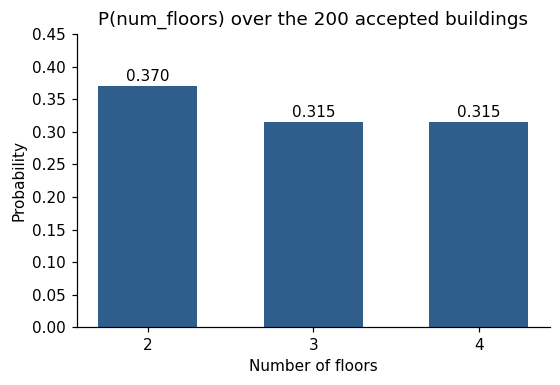

In [20]:
floors = df['floor_plan.num_floors']
p_floor = floors.value_counts(normalize=True).sort_index()
print(p_floor.round(3).to_string())

# Axiom 1: every probability is non-negative
assert (p_floor >= 0).all()
# Axiom 2: the probabilities over the whole sample space add to 1
print('Sum over S =', p_floor.sum())
assert np.isclose(p_floor.sum(), 1.0)
# Axiom 3: additivity for disjoint events (F2 and F3 cannot both happen)
assert (df.F2 & df.F3).sum() == 0
print('P(F2 or F3) =', (df.F2 | df.F3).mean(), ' vs  P(F2)+P(F3) =', p_floor[2] + p_floor[3])
assert np.isclose((df.F2 | df.F3).mean(), p_floor[2] + p_floor[3])

# Complement rule, checked three ways
p_B = df.B_extra_ahu.mean()
p_notB_rule   = 1 - p_B                                  # rule
p_notB_count  = (~df.B_extra_ahu).mean()                 # direct count of the complement
p_notB_config = (df.n_ahus == df['ahu.num_ahus']).mean() # independent: AHU count equals configured count
print(f'P(B) = {p_B:.3f}')
print(f'P(not B): rule = {p_notB_rule:.3f} | count = {p_notB_count:.3f} ({int((~df.B_extra_ahu).sum())}/200) | n_ahus==configured = {p_notB_config:.3f}')
assert np.isclose(p_notB_rule, p_notB_count) and np.isclose(p_notB_count, p_notB_config)

m2_results.update({'P(B)': p_B, 'P(not B)': p_notB_rule,
                   'P(F2)': p_floor[2], 'P(F3)': p_floor[3], 'P(F4)': p_floor[4]})

fig, ax = plt.subplots(figsize=(5.2, 3.6))
bars = ax.bar([str(k) for k in p_floor.index], p_floor.values, color=PALETTE['main'], width=0.6)
for b, v in zip(bars, p_floor.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f'{v:.3f}', ha='center', fontsize=10)
ax.set_ylim(0, 0.45); ax.set_xlabel('Number of floors'); ax.set_ylabel('Probability')
ax.set_title('P(num_floors) over the 200 accepted buildings')
plt.tight_layout(); plt.savefig('figures/fig_floors_pmf.png'); plt.show()

**Result.** P(2) = 0.370, P(3) = 0.315, P(4) = 0.315; all are non-negative, they sum to 1, and F2 and F3 are disjoint so their probabilities add. P(not B) = 1 - 0.73 = 0.27 (54 of 200), identical by the rule, by the direct count, and by checking that `n_ahus` equals the configured AHU count.

**Interpretation.** The empirical floor distribution is a valid probability model. Only about 1 building in 4 stays within its configured AHU count; the other 73% need the scenario generator to add air handlers.

## 5.2 Counting techniques (Member 2)

### Application 3 - Counting: combinations, permutations, the multiplication principle

**Question.** How many ways can we select or arrange buildings, and what does that tell us about drawing review samples, assigning train/validation/test roles and covering the configuration space?

**Events and assumptions.** Buildings are distinguishable (each has its own seed), the 200 accepted buildings are the population, and every selection is equally likely. Counting-based probability = favourable selections / all selections.

**Rules and why they fit.**
- *Combinations* C(n, k) = n! / (k!(n-k)!): order does not matter when a reviewer picks 3 buildings to inspect. P(all 3 needed extra AHUs) = C(146,3) / C(200,3), sampling **without replacement** because the same building cannot be picked twice.
- *Permutations* P(n, k) = n! / (n-k)!: order matters when the first building is for train, the second for validation, the third for test.
- *Multiplication principle:* independent choices multiply, so 3 floor options x 5 AHU options x 2 occupant options = 30 configuration cells.
- *Train/test splits:* the number of 140/60 splits is C(200, 140).

In [21]:
n = len(df); n_B = int(df.B_extra_ahu.sum())

# (a) Combinations: 3 buildings picked at random, all needed extra AHUs
p_all3 = comb(n_B, 3) / comb(n, 3)
p_approx = (n_B / n) ** 3                       # with-replacement approximation
p_seq = (n_B/n) * ((n_B-1)/(n-1)) * ((n_B-2)/(n-2))   # picking one at a time, no replacement
print(f'C({n_B},3) / C({n},3) = {comb(n_B,3)} / {comb(n,3)} = {p_all3:.4f}')
print(f'with-replacement approximation 0.73^3 = {p_approx:.4f}  (gap {p_approx - p_all3:+.4f})')
print(f'one-at-a-time product              = {p_seq:.4f}')

# Independent check: enumerate every one of the 1,313,400 triples and count directly
flags = df.B_extra_ahu.tolist()
good = sum(1 for i, j, k in combinations(range(n), 3) if flags[i] and flags[j] and flags[k])
print('Enumerated triples:', comb(n, 3), '| all-three-extra-AHU triples:', good, '| P =', round(good / comb(n, 3), 4))
assert good == comb(n_B, 3) and np.isclose(p_all3, p_seq)

# (b) Permutations vs combinations
print(f'Ordered (train, val, test) triples  P(200,3) = {perm(n,3):,}')
print(f'Unordered triples                   C(200,3) = {comb(n,3):,}')
print(f'Ratio = {perm(n,3) // comb(n,3)} = 3! (the orderings of one triple)')

# (c) Multiplication principle on the configuration space
levels = {'floors': sorted(floors.unique()),
          'num_ahus': sorted(df['ahu.num_ahus'].unique()),
          'occupants': sorted(df['simulation.occupants_per_zone'].unique())}
n_cells = int(np.prod([len(v) for v in levels.values()]))
print('Option counts:', {k: len(v) for k, v in levels.items()}, '->', n_cells, 'possible cells')
cell_counts = df.groupby(['floor_plan.num_floors', 'ahu.num_ahus', 'simulation.occupants_per_zone']).size()
full_index = pd.MultiIndex.from_product(levels.values())
cell_counts = cell_counts.reindex(full_index, fill_value=0)
print(f'Cells observed: {(cell_counts > 0).sum()} of {n_cells}; empty cells: {(cell_counts == 0).sum()}')
print(f'Buildings per cell: min {cell_counts.min()}, max {cell_counts.max()}, uniform expectation {n/n_cells:.1f}')
display(cell_counts.unstack(level=-1).rename_axis(['floors', 'num_ahus']).add_prefix('occupants='))

# (d) Train/test splits
n_splits = comb(200, 140)
assert n_splits == comb(200, 60)
print(f'Possible 140/60 splits: C(200,140) has {len(str(n_splits))} digits (about {n_splits:.2e})')

m2_results.update({'P(all 3 extra AHU, no replacement)': p_all3, 'P(all 3, with-replacement approx)': p_approx,
                   'perm(200,3)': perm(n,3), 'comb(200,3)': comb(n,3), 'config cells observed': int((cell_counts>0).sum())})

C(146,3) / C(200,3) = 508080 / 1313400 = 0.3868
with-replacement approximation 0.73^3 = 0.3890  (gap +0.0022)
one-at-a-time product              = 0.3868
Enumerated triples: 1313400 | all-three-extra-AHU triples: 508080 | P = 0.3868
Ordered (train, val, test) triples  P(200,3) = 7,880,400
Unordered triples                   C(200,3) = 1,313,400
Ratio = 6 = 3! (the orderings of one triple)
Option counts: {'floors': 3, 'num_ahus': 5, 'occupants': 2} -> 30 possible cells
Cells observed: 30 of 30; empty cells: 0
Buildings per cell: min 2, max 12, uniform expectation 6.7


occupants=1  occupants=2
floors num_ahus                          
2      3                   7            7
       4                   3           12
       5                   6           11
       6                   9            9
       7                   6            4
3      3                   4           10
       4                  10            9
       5                   4            4
       6                   5            2
       7                   5           10
4      3                   7            8
       4                   5            6
       5                   4            8
       6                   6            5
       7                  11            3

Possible 140/60 splits: C(200,140) has 52 digits (about 7.04e+51)


**Result.** P(all 3 picked buildings needed extra AHUs) = C(146,3)/C(200,3) = 0.3868. The with-replacement shortcut 0.73^3 = 0.3890 is slightly larger. Enumerating all 1,313,400 triples gives exactly the same count as the formula. There are 7,880,400 ordered (train, validation, test) triples versus 1,313,400 unordered ones (a factor of 3! = 6). All 30 configuration cells occur (2 to 12 buildings each), and there are about 10^52 possible 140/60 splits.

**Interpretation.**
- *Why the small gap:* when a building is picked, it cannot be picked again, so the proportion of "extra-AHU" buildings left drops a little with each pick. With replacement ignores that. The gap is small because 3 is tiny compared with 200.
- *Order:* use combinations when only *which* buildings matter (a review sample) and permutations when *roles* matter (train/validation/test).
- *Coverage:* the sample covers every configuration cell, but with few buildings in some cells (as few as 2), so cell-level statements are noisy.
- *Splits:* the number of possible splits is astronomically large, which is why one fixed split with a fixed seed must be reported to make results reproducible.

## 5.3 The addition rule (Member 2)

### Application 4 - Addition rule: general case and mutually exclusive case

**Question.** (a) What is the probability that a building is large **or** needs an extra AHU? (b) What is the probability that a building has 2 floors **or** 4 floors?

**Events and assumptions.** A = n_zones > 64 (the median), B = extra AHU. A and B can both happen, so they overlap. F2 and F4 describe the same variable and cannot both be true.

**Rules and why they fit.**
- *General addition rule:* P(A or B) = P(A) + P(B) - P(A and B). It fits because A and B overlap; plain addition would count the buildings in both events twice.
- *Mutually exclusive case:* P(F2 or F4) = P(F2) + P(F4), because P(F2 and F4) = 0 and there is nothing to subtract.

In [22]:
A, B = df.A_large, df.B_extra_ahu
p_A, p_B, p_AB = A.mean(), B.mean(), (A & B).mean()

p_or_rule   = p_A + p_B - p_AB                 # general addition rule
p_or_direct = (A | B).mean()                   # direct count: rows where A or B is True
print(f'P(A)={p_A:.3f}  P(B)={p_B:.3f}  P(A and B)={p_AB:.3f}')
print(f'Rule:   {p_A:.3f} + {p_B:.3f} - {p_AB:.3f} = {p_or_rule:.3f}')
print(f'Direct: {int((A | B).sum())}/200 = {p_or_direct:.3f}')
print(f'Naive sum without subtracting = {p_A + p_B:.3f}  (impossible: above 1)')
assert np.isclose(p_or_rule, p_or_direct)

# Complement cross-check: neither large nor extra AHU
print('P(neither) =', round(1 - p_or_rule, 3), '| direct count =', int((~A & ~B).sum()), 'buildings')

# Mutually exclusive case
assert (df.F2 & df.F4).sum() == 0
p_2or4_rule = df.F2.mean() + df.F4.mean()
p_2or4_direct = (df.F2 | df.F4).mean()
print(f'P(F2 or F4): rule {p_2or4_rule:.3f} | direct {p_2or4_direct:.3f} | overlap count {(df.F2 & df.F4).sum()}')
assert np.isclose(p_2or4_rule, p_2or4_direct)

m2_results.update({'P(A and B)': p_AB, 'P(A or B)': p_or_rule, 'P(F2 or F4)': p_2or4_rule})

P(A)=0.490  P(B)=0.730  P(A and B)=0.485
Rule:   0.490 + 0.730 - 0.485 = 0.735
Direct: 147/200 = 0.735
Naive sum without subtracting = 1.220  (impossible: above 1)
P(neither) = 0.265 | direct count = 53 buildings
P(F2 or F4): rule 0.685 | direct 0.685 | overlap count 0


**Result.** P(A or B) = 0.49 + 0.73 - 0.485 = 0.735 (147 of 200 buildings), matching the direct count. P(F2 or F4) = 0.37 + 0.315 = 0.685, with no overlap.

**Interpretation.** Almost every building (73.5%) is either large or needs extra AHUs, and only 53 are neither. The overlap term is large (0.485) because the two events are strongly linked: nearly all large buildings need extra AHUs (the dependence is studied in Applications 6-10). Adding 0.49 + 0.73 would give 1.22, which cannot be a probability, showing why the overlap must be subtracted. For floors the buildings fall into exactly one group, so nothing is subtracted.

## 5.4 The rejected seeds as a second probability model (Member 2)

### Application 5 - Why do seeds fail? Conditional probabilities inside R

**Question.** Given that a seed was rejected, how bad was the failure?

**Events and assumptions.** The sample space is now the 82 rejected seeds, which is the event R from Application 1. Every probability below is therefore conditional on R: P(E | R) = |E and R| / |R|. E1 = exactly 1 undersized zone; E2 = smallest zone under 5 m2; E3 = 3 or more undersized zones. (An "undersized" zone is below the generator's 20 m2 minimum.) These counts were parsed from the rejection text by Member 1.

**Rule and why it fits.** Classical probability on the restricted sample space. This is the first use of conditioning in the notebook, and it fits because the rejected-seed file contains only failures; mixing in the accepted buildings would hide the failure pattern.

,event,count,P(E | R)
0,E1: exactly 1 undersized zone,54,0.659
1,E2: smallest zone < 5 m2,26,0.317
2,E3: 3+ undersized zones,11,0.134


Distribution of n_small_zones: {1: 54, 2: 17, 3: 7, 4: 1, 5: 2, 7: 1}
mean = 1.59, max = 7
P(E1 or E3 | R) = 0.793  (disjoint, so we add)
P(E1 or E2 | R) = 0.829  (overlap 12 subtracted)
Single-zone failures: median smallest zone = 10.0 m2; 12 of 54 were within 5 m2 of the limit


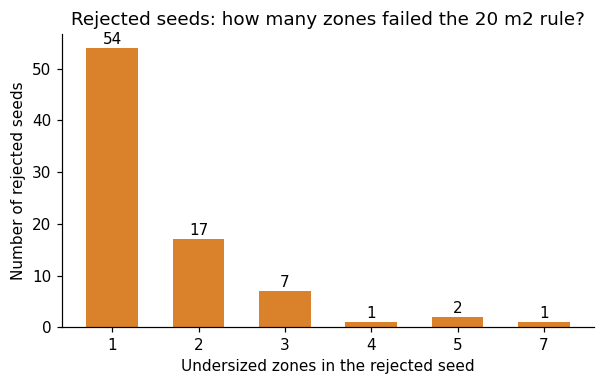

In [23]:
R_n = len(rej)
E1 = rej.n_small_zones == 1
E2 = rej.smallest_m2 < 5
E3 = rej.n_small_zones >= 3

tbl = pd.DataFrame({'event': ['E1: exactly 1 undersized zone', 'E2: smallest zone < 5 m2', 'E3: 3+ undersized zones'],
                    'count': [int(E1.sum()), int(E2.sum()), int(E3.sum())]})
tbl['P(E | R)'] = (tbl['count'] / R_n).round(3)
display(tbl)

dist = rej.n_small_zones.value_counts().sort_index()
print('Distribution of n_small_zones:', dist.to_dict())
print(f'mean = {rej.n_small_zones.mean():.2f}, max = {rej.n_small_zones.max()}')
assert np.isclose(dist.sum(), R_n) and np.isclose((dist / R_n).sum(), 1)   # valid distribution again

# E1 and E3 are disjoint, E1 and E2 overlap -> addition rule on the second model
p_E1orE3 = E1.mean() + E3.mean()
assert np.isclose(p_E1orE3, (E1 | E3).mean())
print(f'P(E1 or E3 | R) = {p_E1orE3:.3f}  (disjoint, so we add)')
print(f'P(E1 or E2 | R) = {E1.mean() + E2.mean() - (E1 & E2).mean():.3f}  (overlap {(E1 & E2).sum()} subtracted)')

# How close were the failures to the 20 m2 limit?
single = rej[E1]
print(f'Single-zone failures: median smallest zone = {single.smallest_m2.median():.1f} m2; '
      f'{int((single.smallest_m2 >= 15).sum())} of {len(single)} were within 5 m2 of the limit')

m2_results.update({'P(E1|R)': E1.mean(), 'P(E2|R)': E2.mean(), 'P(E3|R)': E3.mean(),
                   'mean n_small_zones': rej.n_small_zones.mean()})

fig, ax = plt.subplots(figsize=(5.6, 3.6))
bars = ax.bar(dist.index.astype(str), dist.values, color=PALETTE['accent'], width=0.6)
for b, v in zip(bars, dist.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, str(v), ha='center', fontsize=10)
ax.set_xlabel('Undersized zones in the rejected seed'); ax.set_ylabel('Number of rejected seeds')
ax.set_title('Rejected seeds: how many zones failed the 20 m2 rule?')
plt.tight_layout(); plt.savefig('figures/fig_rejected_small_zones.png'); plt.show()

**Result.** P(E1 | R) = 54/82 = 0.659, P(E2 | R) = 26/82 = 0.317, P(E3 | R) = 11/82 = 0.134. The mean is 1.59 undersized zones per rejected seed (maximum 7).

**Interpretation.** Two out of three failures are caused by a single undersized zone, so for most rejected seeds a single zone is what separates them from acceptance, and only a small share (13%) are badly broken (3+ zones). Single-zone failures are not all near-misses, though: the median offending zone is 10 m2, half the 20 m2 limit, and only 12 of the 54 were within 5 m2 of it. Caution on the remedy: the generator's own rejection message says the minimum room size parameter does not control the realised minimum and recommends **changing the seed**. So the practical action for organizers is to redraw a seed, not to adjust a parameter; this is exactly what the run did, and it costs about 1.4 tries per usable building (1/0.709).

**Limits.** These are counts over 82 rejected seeds of one generator run. They describe how the generator fails, not real buildings.

In [24]:
# Hand-off: rule-based results for Member 4's validation table (and a copy on disk)
m2_results = {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in m2_results.items()}
with open('m2_results.json', 'w') as f:
    json.dump(m2_results, f, indent=2)
pd.Series(m2_results, name='value').to_frame()

,value
P(R),2.907801e-01
P(B),7.300000e-01
P(not B),2.700000e-01
P(F2),3.700000e-01
P(F3),3.150000e-01
P(F4),3.150000e-01
"P(all 3 extra AHU, no replacement)",3.868433e-01
"P(all 3, with-replacement approx)",3.890170e-01
"perm(200,3)",7.880400e+06
"comb(200,3)",1.313400e+06


### 5.5 Conditional probability (Member 3)

**Question.** Are large buildings more likely to need extra air handlers (AHUs) than smaller buildings?

**Events and assumptions.**
- `A` = the building is large: `n_zones > 64` (shared column `A_large`).
- `B` = the building needed at least one AHU beyond its configured number: `ahus_added_beyond_config > 0` (shared column `B_extra_ahu`).
- The 200 accepted buildings are treated as a finite population of equally likely outcomes, so every probability is a count ratio. *Conditioning on `A` means shrinking the sample space to the 98 rows where `A` is true.*
- All results are conditional on the generator having accepted the seed (see Section 3).

**Rule and why it fits.** The definition of conditional probability,

$$P(B \mid A) = \frac{P(A \cap B)}{P(A)} = \frac{N(A \cap B)}{N(A)}, \qquad P(A) > 0.$$

The question compares the extra-AHU rate *inside* two sub-populations (large vs. not large), which is exactly what a conditional probability measures; the unconditional `P(B)` would hide that difference. Direction matters: `P(B | A)` ("among large buildings, how many need extra AHUs?") is **not** `P(A | B)` ("among buildings with extra AHUs, how many are large?"). The second one is answered in Section 5.8.

B_extra_ahu,B: extra AHU,not B: no extra AHU,Total
A_large,,,
A: large (n_zones > 64),97,1,98
not A: not large,49,53,102
Total,146,54,200


P(A)         = 98/200 = 0.4900
P(B)         = 146/200 = 0.7300
P(A and B)   = 97/200 = 0.4850
P(B | A)     = 97/98 = 0.9898   (extra AHU, among LARGE buildings)
P(B | not A) = 49/102 = 0.4804   (extra AHU, among NOT-large buildings)
Difference   = 0.5094;  P(B|A) / P(B) = 1.356


,large means n_zones >,N(large),P(B | large),P(B | not large)
0,40,171,0.830,0.138
1,50,139,0.921,0.295
2,64,98,0.990,0.480
3,80,69,1.000,0.588
4,100,45,1.000,0.652



required AHUs = ceil(n_zones/10) in every row; configured AHUs range 3 to 7
P(B | n_zones > 70) = 1.000  (89 buildings)
Large buildings WITHOUT extra AHU:


,seed,n_zones,ahu.num_ahus,min_ahus_required,floor_plan.num_floors
61,100089,65,7,7,3


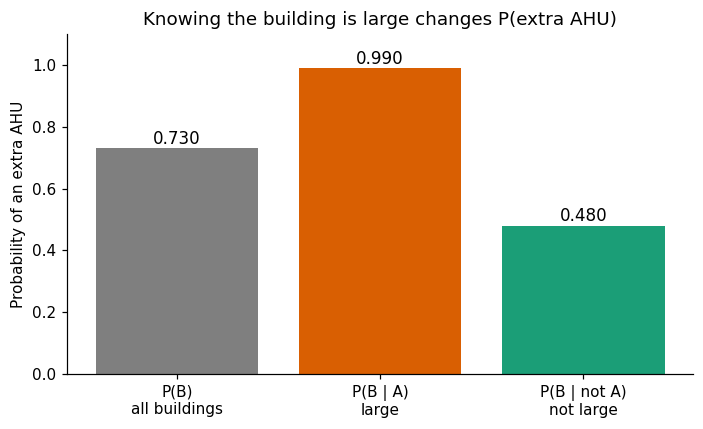

In [25]:
# --- 5.5 Conditional probability -------------------------------------------
import matplotlib.pyplot as plt
from math import isclose

def Pc(a, b):
    '''P(a | b) for two Boolean Series: count(a and b) / count(b).'''
    return (a & b).sum() / b.sum()

A, Bx = df.A_large, df.B_extra_ahu          # shared event columns from Section 4
n = len(df)

# 2 x 2 table of counts: the whole sample space split by A and B
counts_AB = pd.crosstab(
    A.map({True: 'A: large (n_zones > 64)', False: 'not A: not large'}),
    Bx.map({True: 'B: extra AHU', False: 'not B: no extra AHU'}),
    margins=True, margins_name='Total')
display(counts_AB)

# Route 1: definition  P(B|A) = P(A and B) / P(A)
P_A, P_B, P_AB = A.mean(), Bx.mean(), (A & Bx).mean()
P_B_given_A = P_AB / P_A
P_B_given_notA = (~A & Bx).mean() / (~A).mean()

# Route 2: restrict the rows first, then take the share (reduced sample space)
assert isclose(P_B_given_A, Bx[A].mean())
assert isclose(P_B_given_notA, Bx[~A].mean())
assert isclose(P_B_given_A, Pc(Bx, A)) and isclose(P_B_given_notA, Pc(Bx, ~A))

print(f"P(A)         = {A.sum()}/{n} = {P_A:.4f}")
print(f"P(B)         = {Bx.sum()}/{n} = {P_B:.4f}")
print(f"P(A and B)   = {(A & Bx).sum()}/{n} = {P_AB:.4f}")
print(f"P(B | A)     = {(A & Bx).sum()}/{A.sum()} = {P_B_given_A:.4f}   (extra AHU, among LARGE buildings)")
print(f"P(B | not A) = {(~A & Bx).sum()}/{(~A).sum()} = {P_B_given_notA:.4f}   (extra AHU, among NOT-large buildings)")
print(f"Difference   = {P_B_given_A - P_B_given_notA:.4f};  P(B|A) / P(B) = {P_B_given_A / P_B:.3f}")

# Sanity check against the numbers quoted in the interpretation below
assert (round(P_B_given_A, 4), round(P_B_given_notA, 4), round(P_B, 4)) == (0.9898, 0.4804, 0.73)

# Does the picture depend on the 64-zone threshold? (local masks: df is not modified)
rows = []
for t in (40, 50, 64, 80, 100):
    big = df.n_zones > t
    rows.append({'large means n_zones >': t, 'N(large)': int(big.sum()),
                 'P(B | large)': Pc(Bx, big), 'P(B | not large)': Pc(Bx, ~big)})
threshold_check = pd.DataFrame(rows)
display(threshold_check.round(3))

# Why? Look at the generator's own AHU rule (all checked on the data, not assumed)
need_more = df.min_ahus_required > df.ahus_configured
assert (need_more == Bx).all()                                   # B  <=>  required AHUs > configured AHUs
assert (df.min_ahus_required == np.ceil(df.n_zones / 10)).all()  # required AHUs = ceil(n_zones / 10)
big70 = df.n_zones > 70
print("\nrequired AHUs = ceil(n_zones/10) in every row; configured AHUs range", df['ahu.num_ahus'].min(), "to", df['ahu.num_ahus'].max())
print(f"P(B | n_zones > 70) = {Pc(Bx, big70):.3f}  ({int(big70.sum())} buildings)")
print("Large buildings WITHOUT extra AHU:")
display(df.loc[A & ~Bx, ['seed', 'n_zones', 'ahu.num_ahus', 'min_ahus_required', 'floor_plan.num_floors']])

# Chart: unconditional vs conditional extra-AHU probability
fig, ax = plt.subplots(figsize=(6.5, 4))
labels = ['P(B)\nall buildings', 'P(B | A)\nlarge', 'P(B | not A)\nnot large']
vals = [P_B, P_B_given_A, P_B_given_notA]
bars = ax.bar(labels, vals, color=['#7f7f7f', '#d95f02', '#1b9e77'])
for b_, v in zip(bars, vals):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.015, f'{v:.3f}', ha='center', fontsize=11)
ax.set_ylim(0, 1.1); ax.set_ylabel('Probability of an extra AHU')
ax.set_title('Knowing the building is large changes P(extra AHU)')
plt.tight_layout(); plt.show()

**Interpretation (5.5).** Among the 98 large buildings, 97 needed extra AHUs: `P(B | A) = 97/98 = 0.990`. Among the 102 not-large buildings only 49 did: `P(B | not A) = 49/102 = 0.480`. The unconditional `P(B) = 0.730` sits in between because it averages the two groups. Learning that a building is large raises the chance of an extra AHU by about 51 percentage points, so size is a very strong predictor of `B`.

The data shows why: the generator requires `ceil(n_zones / 10)` AHUs and only configures 3 to 7 of them, so a building has an extra AHU exactly when the required number exceeds the configured number. Any building with more than 70 zones needs at least 8 AHUs and therefore *always* has extra ones (`P = 1.000`); the single large building without an extra AHU has 65 zones and 7 configured AHUs. The gap between large and not-large remains big for every threshold in the table, so it is not an artefact of choosing the median. This is a mechanical rule of the generator, i.e. an association in generated data, not a causal finding about real buildings.

### 5.6 Multiplication rule and chain rule (Member 3)

**Question.** What share of *all* buildings are both large and need extra AHUs, and can we build that joint probability from a marginal and a conditional probability? Can the same idea handle three events (4 floors, large, extra AHU)?

**Events and assumptions.** `A` and `B` as in 5.5; `F4` = the building has 4 floors (shared column `F4`). Same finite-population, equally-likely-rows assumption.

**Rule and why it fits.** The multiplication rule rearranges the definition of conditional probability:

$$P(A \cap B) = P(A)\,P(B \mid A) = P(B)\,P(A \mid B).$$

It is the right tool because we already know a conditional probability (`P(B | A)`) and want the joint probability. The plain product `P(A) P(B)` would be correct only if `A` and `B` were independent, which the next calculation shows is *not* the case. For three events the chain rule extends it:

$$P(F_4 \cap A \cap B) = P(F_4)\,P(A \mid F_4)\,P(B \mid F_4 \cap A).$$

In [26]:
# --- 5.6 Multiplication rule and chain rule --------------------------------
F4 = df.F4

# Two events: P(A and B) three ways
joint_rule_1 = P_A * Pc(Bx, A)                 # P(A) * P(B|A)
joint_rule_2 = P_B * Pc(A, Bx)                 # P(B) * P(A|B)   (other order, same answer)
joint_direct = (A & Bx).mean()                 # direct count: 97 / 200
joint_if_independent = P_A * P_B               # what the plain product would give

print(f"P(A) P(B|A)             = {P_A:.4f} x {Pc(Bx, A):.4f} = {joint_rule_1:.4f}")
print(f"P(B) P(A|B)             = {P_B:.4f} x {Pc(A, Bx):.4f} = {joint_rule_2:.4f}")
print(f"direct count (A & B)    = {(A & Bx).sum()}/{n} = {joint_direct:.4f}")
print(f"P(A) P(B) if independent = {joint_if_independent:.4f}   <- does NOT match, so A and B are dependent")
assert isclose(joint_rule_1, joint_direct) and isclose(joint_rule_2, joint_direct)

# Three events: chain rule, each factor read from the data
p1 = F4.mean()                  # P(F4)
p2 = Pc(A, F4)                  # P(A | F4)
p3 = Pc(Bx, F4 & A)             # P(B | F4 and A)
chain = p1 * p2 * p3
chain_direct = (F4 & A & Bx).mean()
print(f"\nP(F4)         = {F4.sum()}/{n} = {p1:.4f}")
print(f"P(A | F4)     = {(F4 & A).sum()}/{F4.sum()} = {p2:.4f}")
print(f"P(B | F4 & A) = {(F4 & A & Bx).sum()}/{(F4 & A).sum()} = {p3:.4f}")
print(f"Chain rule    = {p1:.4f} x {p2:.4f} x {p3:.4f} = {chain:.4f}")
print(f"Direct count  = {(F4 & A & Bx).sum()}/{n} = {chain_direct:.4f}")
assert isclose(chain, chain_direct)

multiplication_table = pd.DataFrame({
    'quantity': ['P(A and B)', 'P(F4 and A and B)'],
    'rule-based': [joint_rule_1, chain],
    'direct count': [joint_direct, chain_direct],
    'count / 200': [f"{(A & Bx).sum()}/{n}", f"{(F4 & A & Bx).sum()}/{n}"]})
display(multiplication_table.round(4))

P(A) P(B|A)             = 0.4900 x 0.9898 = 0.4850
P(B) P(A|B)             = 0.7300 x 0.6644 = 0.4850
direct count (A & B)    = 97/200 = 0.4850
P(A) P(B) if independent = 0.3577   <- does NOT match, so A and B are dependent

P(F4)         = 63/200 = 0.3150
P(A | F4)     = 50/63 = 0.7937
P(B | F4 & A) = 50/50 = 1.0000
Chain rule    = 0.3150 x 0.7937 x 1.0000 = 0.2500
Direct count  = 50/200 = 0.2500


,quantity,rule-based,direct count,count / 200
0,P(A and B),0.485,0.485,97/200
1,P(F4 and A and B),0.250,0.250,50/200


**Interpretation (5.6).** About 48.5% of all accepted buildings are both large and need extra AHUs (`0.49 x 0.990 = 0.485 = 97/200`). If size and the extra-AHU need were independent we would expect only `0.49 x 0.73 = 0.358`, so the multiplication rule with the *conditional* factor is the correct way to get the joint probability here; the gap between 0.358 and 0.485 is itself evidence of dependence (formally assessed in Section 5.9 by Member 4). The chain rule shows the structure of the biggest group: 31.5% of buildings have 4 floors, 79.4% of those are large, and *every* 4-floor large building needs extra AHUs (`P(B | F4 and A) = 1`), giving 25% of all buildings. The rule-based and direct values agree exactly because both use the same 200-row population.

### 5.7 Total probability (Member 3)

**Question.** Can we recover the overall chance of an extra AHU, `P(B)`, from the floor-level extra-AHU rates and the floor mix alone, without ever counting `B` over all 200 rows?

**Events and assumptions.** The partition is `F2, F3, F4` (2, 3 or 4 floors). For the law to apply the events must be **mutually exclusive** and **exhaustive**, and `P(F_k) > 0`. This is checked in code (every building has exactly one floor count; 74 + 63 + 63 = 200). A second partition, `A` / `not A`, is used as a cross-check.

**Rule and why it fits.** The law of total probability:

$$P(B) = \sum_{k=2}^{4} P(B \mid F_k)\,P(F_k).$$

It fits because the extra-AHU rate clearly differs by floor count (we expect it to rise with floors), so `P(B)` is a weighted average of the group rates with the share of each group as weight. It is also the denominator needed for Bayes' theorem in Section 5.8.

In [27]:
# --- 5.7 Total probability ---------------------------------------------------
# 1) Check that F2, F3, F4 form a partition
floor_events = {k: df[f'F{k}'] for k in (2, 3, 4)}
assert ((df.F2.astype(int) + df.F3.astype(int) + df.F4.astype(int)) == 1).all()   # exactly one per row
assert sum(int(f.sum()) for f in floor_events.values()) == n                       # 74 + 63 + 63 = 200

# 2) Ingredients: P(F_k) and P(B | F_k)
pF   = {k: df[f'F{k}'].mean() for k in (2, 3, 4)}
pB_F = {k: Pc(Bx, df[f'F{k}']) for k in (2, 3, 4)}

# 3) Total probability
pB_total = sum(pB_F[k] * pF[k] for k in (2, 3, 4))

total_prob_table = pd.DataFrame({
    'floors': [2, 3, 4],
    'N(F_k)': [int(floor_events[k].sum()) for k in (2, 3, 4)],
    'P(F_k)': [pF[k] for k in (2, 3, 4)],
    'N(B and F_k)': [int((floor_events[k] & Bx).sum()) for k in (2, 3, 4)],
    'P(B | F_k)': [pB_F[k] for k in (2, 3, 4)],
    'P(B | F_k) x P(F_k)': [pB_F[k] * pF[k] for k in (2, 3, 4)]})
display(total_prob_table.round(4))
print(f"Total probability  P(B) = {' + '.join(f'{pB_F[k] * pF[k]:.3f}' for k in (2, 3, 4))} = {pB_total:.4f}")
print(f"Direct count       P(B) = {Bx.sum()}/{n} = {Bx.mean():.4f}")
assert isclose(pB_total, Bx.mean())

# 4) Cross-check with a different partition: A and not A
pB_total_A = P_A * Pc(Bx, A) + (1 - P_A) * Pc(Bx, ~A)
print(f"Partition A / not A: {P_A:.3f} x {Pc(Bx, A):.4f} + {1 - P_A:.3f} x {Pc(Bx, ~A):.4f} = {pB_total_A:.4f}")
assert isclose(pB_total_A, Bx.mean())

# 5) Joint probability table floors x extra AHU (the pieces of the law; reusable for a heatmap)
joint_F_B = pd.crosstab(df['floor_plan.num_floors'], Bx, normalize='all')
joint_F_B.columns = ['no extra AHU (not B)', 'extra AHU (B)']
joint_F_B.index.name = 'floors'
display(joint_F_B.round(4))
assert isclose(joint_F_B['extra AHU (B)'].sum(), pB_total)    # column sum = P(B)

,floors,N(F_k),P(F_k),N(B and F_k),P(B | F_k),P(B | F_k) x P(F_k)
0,2,74,0.370,39,0.5270,0.195
1,3,63,0.315,49,0.7778,0.245
2,4,63,0.315,58,0.9206,0.290


Total probability  P(B) = 0.195 + 0.245 + 0.290 = 0.7300
Direct count       P(B) = 146/200 = 0.7300
Partition A / not A: 0.490 x 0.9898 + 0.510 x 0.4804 = 0.7300


,no extra AHU (not B),extra AHU (B)
floors,,
2,0.175,0.195
3,0.070,0.245
4,0.025,0.290


**Interpretation (5.7).** The extra-AHU rate climbs with the number of floors: `P(B | F2) = 39/74 = 0.527`, `P(B | F3) = 49/63 = 0.778`, `P(B | F4) = 58/63 = 0.921`. Weighting these rates by the floor mix (0.370, 0.315, 0.315) gives `0.195 + 0.245 + 0.290 = 0.730`, exactly the direct count `146/200`. The agreement is exact (not approximate) because the same 200 buildings feed both routes and the partition is valid; a mismatch would signal an overlapping or incomplete partition. The `A` / `not A` partition gives the same 0.730, showing that the result does not depend on which partition is used. More floors means more zones in this generator, which is why taller buildings more often need extra AHUs; the overall 73% is a blend of a roughly 50/50 situation for 2-floor buildings and a near-certain one for 4-floor buildings.

### 5.8 Bayes' theorem (Member 3)

**Question.** Suppose we are told only that a building needed extra AHUs. How likely is it to have 4 floors (and how likely is it to be large)? Conversely, how does the answer change if we are told it needed *no* extra AHU?

**Events and assumptions.** Prior: `P(F_k)` (floor mix before any evidence). Evidence: `B` (extra AHU observed). Posterior: `P(F_k | B)`. We know the forward rates `P(B | F_k)` from 5.7 and want to reverse the direction of the conditioning. Finite population of 200 accepted buildings, as before.

**Rule and why it fits.** Bayes' theorem:

$$P(F_k \mid B) = \frac{P(B \mid F_k)\,P(F_k)}{P(B)}, \qquad P(B) = \sum_j P(B \mid F_j)\,P(F_j).$$

It fits because the data naturally give "given the floors, how often is there an extra AHU?" but the question asks the reverse, "given an extra AHU, what are the floors?". The denominator is the total-probability result from 5.7, so 5.7 and 5.8 work as a pair. The same formula answers `P(A | B) = P(B | A) P(A) / P(B)`.

,floors,prior P(F_k),likelihood P(B | F_k),posterior P(F_k | B),direct count among B,posterior P(F_k | not B)
0,2,0.370,0.5270,0.2671,39/146,0.6481
1,3,0.315,0.7778,0.3356,49/146,0.2593
2,4,0.315,0.9206,0.3973,58/146,0.0926


P(F4 | B) = (0.9206 x 0.315) / 0.730 = 0.3973   direct: 58/146 = 0.3973
P(A | B) = (0.9898 x 0.49) / 0.73 = 0.6644   direct: 97/146 = 0.6644   prior P(A) = 0.49

P(B | A) = 0.990  vs  P(A | B) = 0.664   (not the same question!)


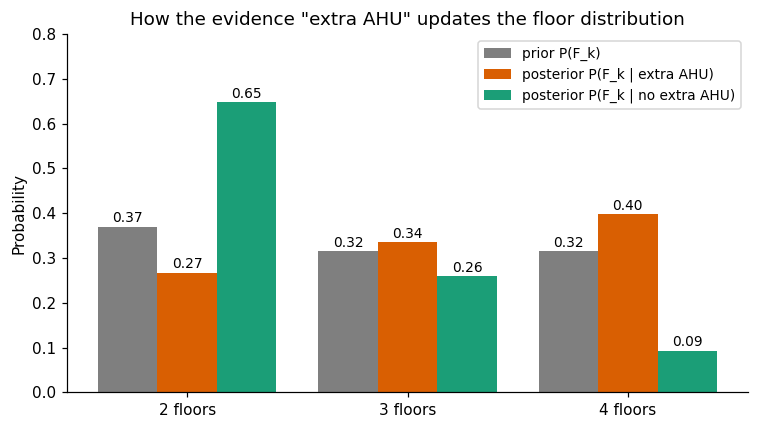

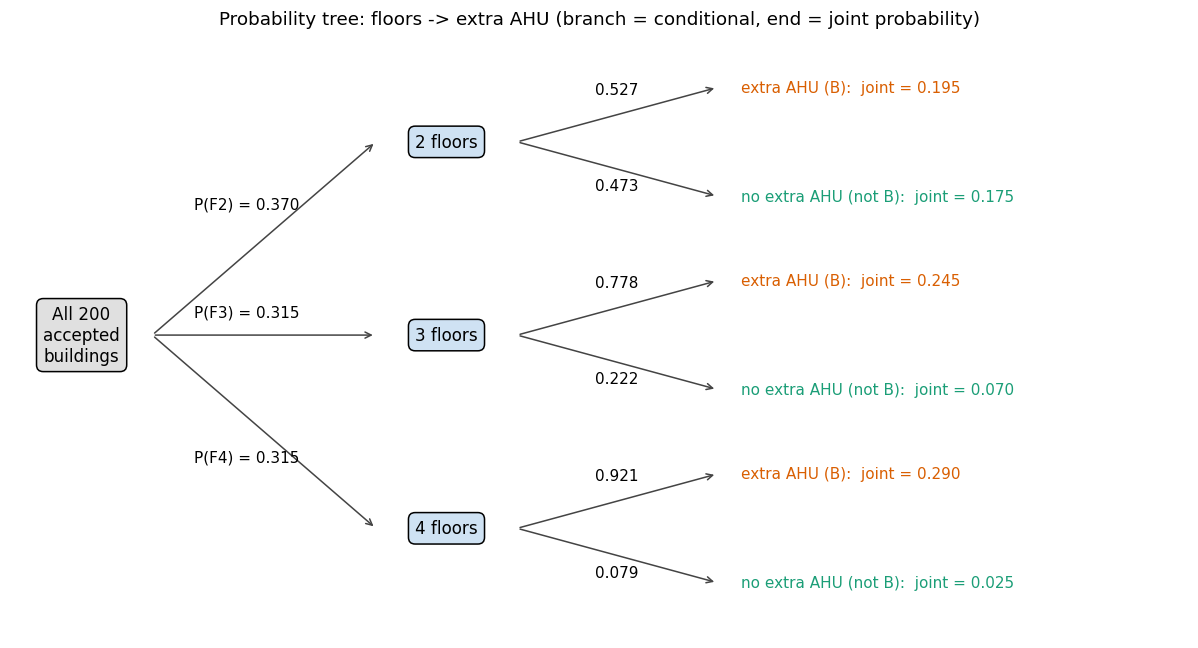

In [28]:
# --- 5.8 Bayes' theorem ------------------------------------------------------
# Posterior P(F_k | B) for every floor count (evidence: an extra AHU was needed)
post = {k: pB_F[k] * pF[k] / pB_total for k in (2, 3, 4)}
post_F4 = post[4]
direct_post = {k: Pc(df[f'F{k}'], Bx) for k in (2, 3, 4)}        # direct count among B rows
for k in (2, 3, 4):
    assert isclose(post[k], direct_post[k])
assert isclose(sum(post.values()), 1.0)                          # posteriors form a distribution

# Evidence in the other direction: no extra AHU (not B)
pnotB = 1 - pB_total
post_notB = {k: (1 - pB_F[k]) * pF[k] / pnotB for k in (2, 3, 4)}
for k in (2, 3, 4):
    assert isclose(post_notB[k], Pc(df[f'F{k}'], ~Bx))

prior_posterior = pd.DataFrame({
    'floors': [2, 3, 4],
    'prior P(F_k)': [pF[k] for k in (2, 3, 4)],
    'likelihood P(B | F_k)': [pB_F[k] for k in (2, 3, 4)],
    'posterior P(F_k | B)': [post[k] for k in (2, 3, 4)],
    'direct count among B': [f"{int((df[f'F{k}'] & Bx).sum())}/{int(Bx.sum())}" for k in (2, 3, 4)],
    'posterior P(F_k | not B)': [post_notB[k] for k in (2, 3, 4)]})
display(prior_posterior.round(4))
print(f"P(F4 | B) = ({pB_F[4]:.4f} x {pF[4]:.3f}) / {pB_total:.3f} = {post_F4:.4f}   direct: 58/146 = {58 / 146:.4f}")

# Second Bayes question: P(A | B), "of the buildings with extra AHUs, how many are large?"
post_A_given_B = Pc(Bx, A) * P_A / P_B
print(f"P(A | B) = ({Pc(Bx, A):.4f} x {P_A:.2f}) / {P_B:.2f} = {post_A_given_B:.4f}   direct: 97/146 = {97 / 146:.4f}   prior P(A) = {P_A:.2f}")
assert isclose(post_A_given_B, Pc(A, Bx)) and isclose(post_F4, 58 / 146)

# Direction check: the two conditional probabilities are very different
print(f"\nP(B | A) = {Pc(Bx, A):.3f}  vs  P(A | B) = {Pc(A, Bx):.3f}   (not the same question!)")

# Chart 1: prior vs posterior
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3); w = 0.27
ax.bar(x - w, [pF[k] for k in (2, 3, 4)], w, label='prior P(F_k)', color='#7f7f7f')
ax.bar(x, [post[k] for k in (2, 3, 4)], w, label='posterior P(F_k | extra AHU)', color='#d95f02')
ax.bar(x + w, [post_notB[k] for k in (2, 3, 4)], w, label='posterior P(F_k | no extra AHU)', color='#1b9e77')
for xs, vals in ((x - w, [pF[k] for k in (2, 3, 4)]), (x, [post[k] for k in (2, 3, 4)]), (x + w, [post_notB[k] for k in (2, 3, 4)])):
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 0.01, f'{v:.2f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['2 floors', '3 floors', '4 floors'])
ax.set_ylabel('Probability'); ax.set_ylim(0, 0.8)
ax.set_title('How the evidence "extra AHU" updates the floor distribution')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

# Chart 2: probability tree floors -> extra AHU (branch probabilities and joint probabilities)
fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
arrow = dict(arrowstyle='->', color='#444444')
ax.text(0.06, 0.5, 'All 200\naccepted\nbuildings', ha='center', va='center', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', fc='#e0e0e0'))
floor_y = {2: 0.82, 3: 0.50, 4: 0.18}
for k in (2, 3, 4):
    fy = floor_y[k]
    ax.annotate('', xy=(0.31, fy), xytext=(0.12, 0.5), arrowprops=arrow)
    ax.text(0.20, (0.5 + fy) / 2 + (0.05 if k == 2 else -0.05 if k == 4 else 0.03),
            f'P(F{k}) = {pF[k]:.3f}', ha='center', fontsize=10)
    ax.text(0.37, fy, f'{k} floors', ha='center', va='center', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.4', fc='#cfe2f3'))
    for is_b, dy, lab, col in ((True, 0.09, 'extra AHU (B)', '#d95f02'), (False, -0.09, 'no extra AHU (not B)', '#1b9e77')):
        ly = fy + dy
        p_cond = pB_F[k] if is_b else 1 - pB_F[k]
        ax.annotate('', xy=(0.60, ly), xytext=(0.43, fy), arrowprops=arrow)
        ax.text(0.515, (fy + ly) / 2 + (0.035 if is_b else -0.035), f'{p_cond:.3f}', ha='center', fontsize=10)
        ax.text(0.62, ly, f'{lab}:  joint = {pF[k] * p_cond:.3f}', va='center', fontsize=10, color=col)
ax.set_title('Probability tree: floors -> extra AHU (branch = conditional, end = joint probability)', fontsize=12)
plt.tight_layout(); plt.show()

**Interpretation (5.8).** *Prior* = what we believed about the floor count before seeing any evidence (31.5% four-floor); *posterior* = the updated belief after learning the building needed extra AHUs. Seeing that evidence raises the probability of 4 floors from 0.315 to `(58/63 x 0.315) / 0.73 = 0.397` (`= 58/146`, matching the direct count) and lowers the probability of 2 floors from 0.370 to 0.267. Hearing "no extra AHU" pushes the other way: the 4-floor share falls to 0.093 (5 of 54 buildings) and 2-floor buildings become the majority (0.648). In the same way, among buildings with extra AHUs about two thirds are large (`P(A | B) = 97/146 = 0.664`, up from the prior 0.49).

Two cautions. First, `P(B | A) = 0.990` and `P(A | B) = 0.664` answer different questions; the first is high because almost all large buildings need extra AHUs, the second is lower because many *not-large* buildings (49 of 146) also need them. Second, the posterior is a re-weighting of the observed buildings, not a causal statement: the extra AHU is "evidence" about the floors only because the generator links floors, size and AHU requirements.

#### Hand-off to Member 4 (validation): rule-based results from Sections 5.5-5.8

All values below are pulled live from the cells above (nothing is typed in by hand). Member 4's validation cells can use the variables `Pc`, `A`, `Bx`, `pF`, `pB_F`, `pB_total`, `post_F4` and the dictionary `m3_results`.

In [29]:
# --- Hand-off dictionary: rule-based values (route 1 of the three-way validation) ---
m3_results = {
    'P(B|A)':          P_B_given_A,
    'P(B|not A)':      P_B_given_notA,
    'P(A and B)':      joint_rule_1,                 # multiplication rule
    'P(F4 and A and B)': chain,                      # chain rule
    'P(B)':            pB_total,                     # total probability
    'P(F4|B)':         post_F4,                      # Bayes
    'P(A|B)':          post_A_given_B,               # Bayes
    'P(F2|B)':         post[2],
    'P(F3|B)':         post[3],
}
display(pd.Series(m3_results, name='rule-based value').round(4).to_frame())

,rule-based value
P(B|A),0.9898
P(B|not A),0.4804
P(A and B),0.4850
P(F4 and A and B),0.2500
P(B),0.7300
P(F4|B),0.3973
P(A|B),0.6644
P(F2|B),0.2671
P(F3|B),0.3356


In [30]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import comb, perm, isclose
from pathlib import Path
from scipy.stats import chi2_contingency
from IPython.display import display

EVENTS = ["A_large", "B_extra_ahu", "F2", "F3", "F4", "O2"]

def rebuild_member1_df():
    """Same steps as Member 1 (Sections 1, 3, 4). Used only if df is not already in memory."""
    need = ["buildings_200_features.csv", "rejected_seeds.csv", "feature_catalog.csv"]
    folders = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive/stats_project")]
    data_dir = next((p for p in folders if (p / need[0]).exists()), None)
    if data_dir is None:
        from google.colab import files
        print("Upload buildings_200_features.csv now (rejected_seeds / feature_catalog are optional here)")
        files.upload(); data_dir = Path.cwd()
    raw = pd.read_csv(data_dir / need[0])                      # raw table is never modified
    d = raw.copy()
    d.columns = [c.split("__", 1)[1] for c in d.columns]        # drop only the first prefix
    d = d.drop(columns=[c for c in d.columns if d[c].nunique(dropna=False) == 1])   # 17 constants
    d["A_large"]     = d.n_zones > d.n_zones.median()           # strict >, median = 64
    d["B_extra_ahu"] = d.ahus_added_beyond_config > 0
    for k in (2, 3, 4):
        d[f"F{k}"] = d["floor_plan.num_floors"] == k
    d["O2"] = d["simulation.occupants_per_zone"] == 2
    return raw, d

if "df" not in globals() or not all(e in df.columns for e in EVENTS):
    df_raw, df = rebuild_member1_df()
    print("Stand-alone mode: rebuilt df from the CSV")
else:
    print("Using Member 1's df from this notebook")

# --- Member 4's own additions (df_raw untouched; N7 added to the analysis frame only) ---
med = df.n_zones.median()                          # 64
df["N7"] = df["ahu.num_ahus"] == 7                 # 7 AHUs were configured
cut = df.n_zones.quantile(0.95)                    # 157.7 zones
df_trim = df[df.n_zones <= cut].copy()             # 5% of buildings with the most zones removed
n = len(df)

print("df:", df.shape, "| df_trim:", df_trim.shape, "| cut =", round(cut, 1))
counts = df[EVENTS + ["N7"]].sum()
print(counts.to_dict())
assert n == 200 and len(df_trim) == 190
assert counts.to_dict() == {"A_large": 98, "B_extra_ahu": 146, "F2": 74, "F3": 63,
                            "F4": 63, "O2": 108, "N7": 39}, "event counts differ from Member 1 - check df"

Using Member 1's df from this notebook
df: (200, 44) | df_trim: (190, 44) | cut = 157.7
{'A_large': 98, 'B_extra_ahu': 146, 'F2': 74, 'F3': 63, 'F4': 63, 'O2': 108, 'N7': 39}


## 5.9 Independence

**Question.** Does knowing one fact about a building change the chance of another fact?

**Events and assumptions.** `A_large` (n_zones > 64, 98 buildings), `B_extra_ahu` (AHUs added beyond configured, 146), `F2/F3/F4` (2/3/4 floors: 74/63/63), `O2` (2 occupants per zone, 108), `N7` (7 AHUs configured, 39). The 200 accepted buildings are treated as equally likely draws from the generator; tolerance is 2 standard errors.

**Rule and why it fits.** Two events are independent if P(A and B) = P(A) x P(B). We compare the actual joint probability with this product. With only 200 rows the gap is never exactly 0, so we call a pair *dependent* only when the gap is bigger than 2 SE of the gap, where SE = sqrt( P(A)(1-P(A)) P(B)(1-P(B)) / n ). A chi-square p-value is a cross-check. Lift = P(A and B) / (P(A)P(B)); 1 means independent, above 1 means they occur together more than chance, below 1 less than chance.

In [31]:
def indep(a, b, name):
    pa, pb, pab = a.mean(), b.mean(), (a & b).mean()
    pp = pa * pb                                                   # expected joint if independent
    se = (pa*(1-pa)*pb*(1-pb) / n) ** 0.5                          # standard error of the gap
    p_chi2 = chi2_contingency(pd.crosstab(a, b), correction=False)[1]   # cross-check only
    return dict(pair=name, P_A=pa, P_B=pb, P_AandB=pab, P_A_x_P_B=pp, diff=pab-pp,
                lift=pab/pp, two_SE=2*se,
                verdict="dependent" if abs(pab-pp) > 2*se else "consistent with independence",
                p_chi2=p_chi2)

pairs = [("A_large","B_extra_ahu"), ("F4","B_extra_ahu"), ("O2","B_extra_ahu"),
         ("F4","O2"), ("F4","N7"), ("O2","A_large"),
         ("F2","B_extra_ahu"), ("F3","B_extra_ahu"), ("F4","A_large"),
         ("N7","B_extra_ahu"), ("N7","A_large"), ("O2","N7")]
indep_table = pd.DataFrame([indep(df[a], df[b], f"{a} vs {b}") for a, b in pairs])
display(indep_table.round(4))

dep = set(indep_table.loc[indep_table.verdict == "dependent", "pair"])
assert dep == {"A_large vs B_extra_ahu", "F4 vs B_extra_ahu", "F2 vs B_extra_ahu",
               "F4 vs A_large", "N7 vs B_extra_ahu"}, dep
print("Dependent pairs:", sorted(dep))

,pair,P_A,P_B,P_AandB,P_A_x_P_B,diff,lift,two_SE,verdict,p_chi2
0,A_large vs B_extra_ahu,0.490,0.730,0.485,0.3577,0.1273,1.3559,0.0314,dependent,0.0000
1,F4 vs B_extra_ahu,0.315,0.730,0.290,0.2300,0.0600,1.2611,0.0292,dependent,0.0000
2,O2 vs B_extra_ahu,0.540,0.730,0.395,0.3942,0.0008,1.0020,0.0313,consistent with independence,0.9592
3,F4 vs O2,0.315,0.540,0.150,0.1701,-0.0201,0.8818,0.0327,consistent with independence,0.2195
4,F4 vs N7,0.315,0.195,0.070,0.0614,0.0086,1.1396,0.0260,consistent with independence,0.5099
5,O2 vs A_large,0.540,0.490,0.280,0.2646,0.0154,1.0582,0.0352,consistent with independence,0.3820
6,F2 vs B_extra_ahu,0.370,0.730,0.195,0.2701,-0.0751,0.7220,0.0303,dependent,0.0000
7,F3 vs B_extra_ahu,0.315,0.730,0.245,0.2300,0.0151,1.0654,0.0292,consistent with independence,0.3020
8,F4 vs A_large,0.315,0.490,0.250,0.1543,0.0957,1.6197,0.0328,dependent,0.0000
9,N7 vs B_extra_ahu,0.195,0.730,0.100,0.1424,-0.0424,0.7025,0.0249,dependent,0.0007


Dependent pairs: ['A_large vs B_extra_ahu', 'F2 vs B_extra_ahu', 'F4 vs A_large', 'F4 vs B_extra_ahu', 'N7 vs B_extra_ahu']


**Interpretation (5.9).** Five pairs are dependent: A_large/F4/F2/N7 each with the AHU outcome or size. They all trace back to the generator's capacity rule (required AHUs = ceil(zones / 10) versus 3 to 7 configured AHUs). The seven consistent pairs are settings the generator draws separately (floors, occupants, configured AHUs) or things outside the AHU rule (occupants). "Consistent with independence" does **not** prove independence; 200 rows cannot prove it. These are associations in generated data, not causes. **Limitation:** the 2 SE rule is a rule of thumb, so we also report the chi-square p-value.

### Lift chart
Lift = P(A and B) / (P(A) x P(B)); the black line at 1 means independent.

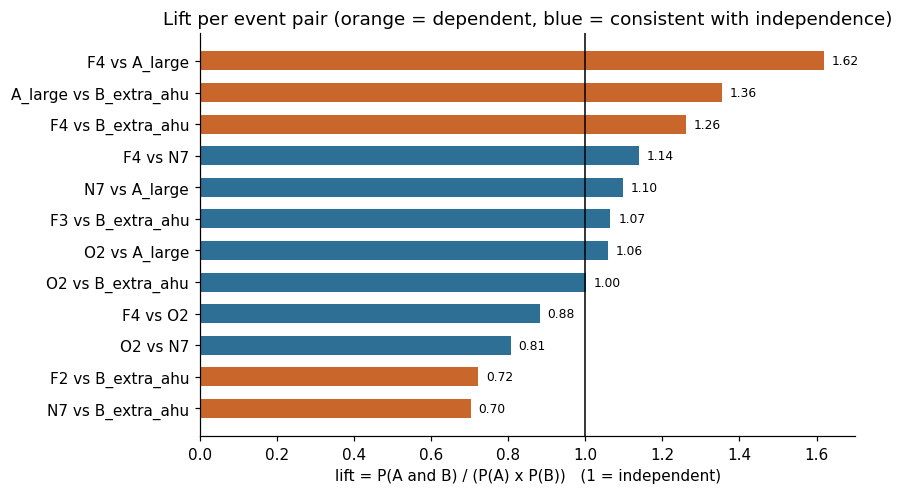

In [32]:
t = indep_table.sort_values("lift")
colors = ["#C8662B" if v == "dependent" else "#2E6F95" for v in t.verdict]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(t.pair, t.lift, color=colors, height=0.6)
ax.axvline(1, color="black", lw=1)
for y, l in enumerate(t.lift):
    ax.text(l + 0.02, y, f"{l:.2f}", va="center", fontsize=8)
ax.set(title="Lift per event pair (orange = dependent, blue = consistent with independence)",
       xlabel="lift = P(A and B) / (P(A) x P(B))   (1 = independent)")
plt.tight_layout(); plt.savefig("lift_chart.png", dpi=150); plt.show()

## 6. Validation

### 6.1 Three-way validation table

**Question.** Do independent routes give the same probabilities?

**Events and assumptions.** Same 200 rows, seed 42. Monte Carlo draws 100,000 buildings from the 200 *with replacement*.

**Rule and why it fits.** Each result is computed (1) by its probability rule, (2) by directly counting rows, (3) by Monte Carlo. Rule and direct count are the same number written two ways, so they must match to rounding (< 1e-12). Monte Carlo is random, so it differs by sampling noise only (about sqrt(p(1-p)/100000) = 0.0016 at most). If Member 3's `m3_results` is in memory, its stored values are checked against ours as well.

In [33]:
def Pc(a, b):                       # P(a | b) = count(a and b) / count(b)
    return (a & b).sum() / b.sum()

A, Bx = df.A_large, df.B_extra_ahu
pF  = {k: df[f"F{k}"].mean() for k in (2, 3, 4)}
pBF = {k: Pc(Bx, df[f"F{k}"]) for k in (2, 3, 4)}
pB_total = sum(pBF[k] * pF[k] for k in (2, 3, 4))               # total probability
post_F4  = pBF[4] * pF[4] / pB_total                              # Bayes

rng = np.random.default_rng(42)                                   # seed 42 -> same numbers every run
sim = df.loc[rng.choice(df.index, 100_000)]                       # 100,000 draws with replacement
cx  = pd.crosstab(A, Bx)                                          # another route to P(B|A)
sA, sB = sim.A_large, sim.B_extra_ahu

items = [
 ("P(B) total probability",     pB_total, Bx.mean(), sB.mean()),
 ("P(B|A) conditional",         (A & Bx).mean()/A.mean(), Pc(Bx, A), Pc(sB, sA)),
 ("P(A and B) multiplication",  A.mean()*Pc(Bx, A), (A & Bx).mean(), (sA & sB).mean()),
 ("P(A or B) addition",         A.mean()+Bx.mean()-(A & Bx).mean(), (A | Bx).mean(), (sA | sB).mean()),
 ("P(F4|B) Bayes",              post_F4, Pc(df.F4, Bx), Pc(sim.F4, sB)),
 ("P(not B) complement",        1-Bx.mean(), (~Bx).mean(), (~sB).mean()),
]
val = pd.DataFrame(items, columns=["result", "rule", "direct_count", "monte_carlo"])
val["|rule-direct|"] = (val.rule - val.direct_count).abs()
val["|direct-MC|"]   = (val.direct_count - val.monte_carlo).abs()
display(val.round(5))
assert (val["|rule-direct|"] < 1e-12).all(), "rule and direct count must agree exactly - look for a bug"
assert (val["|direct-MC|"] < 0.005).all(), "Monte Carlo too far from direct count"
print("crosstab route P(B|A):", round(cx.loc[True, True] / cx.loc[True].sum(), 4))
print("largest Monte Carlo noise seen:", round(val["|direct-MC|"].max(), 5))

# Optional: compare with Member 3's hand-off values (only if his cells ran in this notebook)
if "m3_results" in globals():
    chk = {"P(B|A)": Pc(Bx, A), "P(A and B)": (A & Bx).mean(), "P(B)": Bx.mean(), "P(F4|B)": Pc(df.F4, Bx)}
    for k, v in chk.items():
        assert isclose(m3_results[k], v, abs_tol=1e-12), f"Member 3 value {k} differs"
    print("Member 3 hand-off values match the direct counts.")
else:
    print("m3_results not in memory (stand-alone mode): Member 3 check skipped.")

,result,rule,direct_count,monte_carlo,|rule-direct|,|direct-MC|
0,P(B) total probability,0.73000,0.73000,0.73079,0.0,0.00079
1,P(B|A) conditional,0.98980,0.98980,0.99031,0.0,0.00051
2,P(A and B) multiplication,0.48500,0.48500,0.48544,0.0,0.00044
3,P(A or B) addition,0.73500,0.73500,0.73554,0.0,0.00054
4,P(F4|B) Bayes,0.39726,0.39726,0.39731,0.0,0.00005
5,P(not B) complement,0.27000,0.27000,0.26921,0.0,0.00079


crosstab route P(B|A): 0.9898
largest Monte Carlo noise seen: 0.00079
Member 3 hand-off values match the direct counts.


**Interpretation (6.1).** Rule and direct count agree exactly (difference 0 up to rounding) because both use the same 200 rows. Monte Carlo differs by at most a few thousandths, which is ordinary sampling noise. If rule and direct count ever differ, look for a wrong denominator, a partition that does not add to 200, different row sets (`df` vs `df_trim`), or different thresholds (`>64` vs `>=64`). **Limitation:** Monte Carlo only re-draws our own 200 rows, so it checks our code, not the real generator.

### 6.2 Counting check (without replacement)

**Question.** If 3 buildings are picked at random without replacement, what is the chance all 3 need extra AHUs?

**Rule and why it fits.** Combinations: C(146,3) / C(200,3), because the order of the 3 buildings does not matter and no building can be picked twice. The shortcut 0.73^3 assumes replacement, so it should be slightly different.

In [34]:
exact = comb(146, 3) / comb(200, 3)
rng = np.random.default_rng(42)
b = df.B_extra_ahu.to_numpy()
hits = sum(b[rng.choice(200, 3, replace=False)].all() for _ in range(100_000))
print(f"exact C(146,3)/C(200,3)          = {exact:.4f}")
print(f"simulation (no replacement)      = {hits/100_000:.4f}")
print(f"with-replacement shortcut 0.73^3 = {0.73**3:.4f}  (gap {0.73**3-exact:+.4f})")
print("ordered triples 200P3 =", perm(200, 3), "| unordered C(200,3) =", comb(200, 3))
assert abs(exact - hits/100_000) < 0.005

exact C(146,3)/C(200,3)          = 0.3868
simulation (no replacement)      = 0.3877
with-replacement shortcut 0.73^3 = 0.3890  (gap +0.0022)
ordered triples 200P3 = 7880400 | unordered C(200,3) = 1313400


**Interpretation (6.2).** The exact value (0.387) and the simulation agree within noise. The with-replacement shortcut is a little too high because drawing without replacement slightly lowers the chance of another B building each time. **Limitation:** the simulation has noise of about 0.002.

### 6.3 Bootstrap (uncertainty)

**Question.** How uncertain is P(B|A) because we only have 200 buildings?

**Rule and why it fits.** Bootstrap: redraw 200 buildings with replacement 2,000 times, recompute P(B|A) each time, and take the middle 95% (2.5th to 97.5th percentile). It needs no formula, which suits a probability that sits near 1.

P(B|A) = 0.9898   95% bootstrap interval [0.9667, 1.0000]   sd = 0.0102


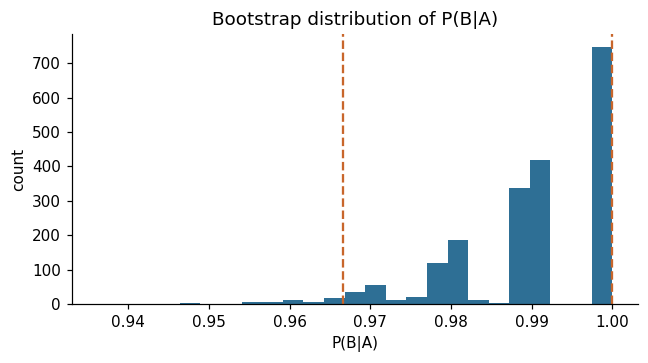

In [35]:
rng = np.random.default_rng(42)
boot = []
for _ in range(2000):
    s = df.loc[rng.choice(df.index, len(df))]
    if s.A_large.sum() > 0:
        boot.append(Pc(s.B_extra_ahu, s.A_large))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"P(B|A) = {Pc(Bx, A):.4f}   95% bootstrap interval [{lo:.4f}, {hi:.4f}]   sd = {np.std(boot):.4f}")
plt.figure(figsize=(6, 3.4)); plt.hist(boot, bins=25, color="#2E6F95")
plt.axvline(lo, color="#C8662B", ls="--"); plt.axvline(hi, color="#C8662B", ls="--")
plt.title("Bootstrap distribution of P(B|A)"); plt.xlabel("P(B|A)"); plt.ylabel("count")
plt.tight_layout(); plt.savefig("bootstrap_hist.png", dpi=150); plt.show()
assert lo <= Pc(Bx, A) <= hi

**Interpretation (6.3).** P(B|A) = 97/98 = 0.990, with a 95% interval of about 0.967 to 1.000. The interval touches 1 because many resamples contain no large building without extra AHUs. So the true rate is very likely above 0.96. **Limitation:** the bootstrap only reflects the 200 accepted buildings, not the generator's rejection step.

### 6.4 Sensitivity (do our own choices change the answer?)

**Question.** Does removing the 5% biggest buildings, or moving the "large" threshold, change the main results?

**Rule and why it fits.** We recompute the same probabilities on `df_trim` (190 rows, zones <= 157.7) and for thresholds 50, 64, 80 and 100. Stable results mean the conclusion does not depend on one buildings group or on the median convention.

In [36]:
print(f"cut = {cut:.1f} zones; rows {len(df)} -> {len(df_trim)}  ({len(df)-len(df_trim)} buildings removed)")
A2, B2 = df_trim.n_zones > med, df_trim.B_extra_ahu               # same threshold (64)
sens = pd.DataFrame({
    "full (200)": [Bx.mean(), Pc(Bx, A), Pc(Bx, ~A), Pc(df.F4, Bx), df.O2.mean()],
    "trimmed":    [B2.mean(), Pc(B2, A2), Pc(B2, ~A2), Pc(df_trim.F4, B2), df_trim.O2.mean()],
}, index=["P(B)", "P(B|A)", "P(B|not A)", "P(F4|B)", "P(O2)"])
sens["change"] = sens["trimmed"] - sens["full (200)"]
display(sens.round(4))
rows = []
for thr in (50, 64, 80, 100):
    a = df.n_zones > thr
    rows.append((thr, a.mean(), Pc(Bx, a), Pc(Bx, ~a)))
thr_table = pd.DataFrame(rows, columns=["zone threshold", "P(large)", "P(B|large)", "P(B|not large)"])
display(thr_table.round(3))

cut = 157.7 zones; rows 200 -> 190  (10 buildings removed)


,full (200),trimmed,change
P(B),0.7300,0.7158,-0.0142
P(B|A),0.9898,0.9886,-0.0012
P(B|not A),0.4804,0.4804,0.0000
P(F4|B),0.3973,0.3603,-0.0370
P(O2),0.5400,0.5474,0.0074


,zone threshold,P(large),P(B|large),P(B|not large)
0,50,0.695,0.921,0.295
1,64,0.490,0.990,0.480
2,80,0.345,1.000,0.588
3,100,0.225,1.000,0.652


**Interpretation (6.4).** After removing the 10 buildings above 157.7 zones, P(B|A) barely moves (0.990 to 0.989) and P(B) falls by about 1 point (0.730 to 0.716) and P(F4|B) by about 4 points (0.397 to 0.360). At every threshold large buildings are far more likely to need extra AHUs than not-large ones. So the main conclusion does not depend on the 5% largest buildings or on choosing 64. **Limitation:** trimming changes the population, so the probabilities are for "buildings up to 157.7 zones", not for all accepted buildings.

### Save results for Member 5

In [37]:
member4_results = dict(independence=indep_table, validation=val, boot_ci=(lo, hi), sensitivity=sens, thresholds=thr_table)
indep_table.round(4).to_csv("m4_independence.csv", index=False)
val.round(5).to_csv("m4_validation.csv", index=False)
sens.round(4).to_csv("m4_sensitivity.csv")
print("saved: m4_independence.csv, m4_validation.csv, m4_sensitivity.csv, lift_chart.png, bootstrap_hist.png")
print("Member 5 can read the dictionary member4_results (keys:", list(member4_results), ")")

saved: m4_independence.csv, m4_validation.csv, m4_sensitivity.csv, lift_chart.png, bootstrap_hist.png
Member 5 can read the dictionary member4_results (keys: ['independence', 'validation', 'boot_ci', 'sensitivity', 'thresholds'] )


## 7. Insights and limitations (Member 5)

Summarize findings with numbers, discuss limitations, and explain relevance to the Smart Buildings competition.

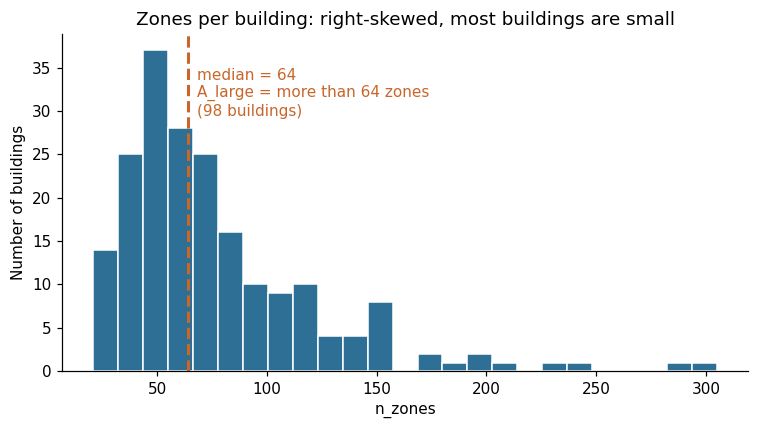

In [38]:
import os
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)

med = df.n_zones.median()          # 64
n_large = int(df.A_large.sum())    # buildings with n_zones > 64

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df.n_zones, bins=25, color='#2E6F95', edgecolor='white')
ax.axvline(med, color='#C8662B', lw=2, ls='--')
ax.text(med + 4, ax.get_ylim()[1] * 0.9,
        f'median = {med:.0f}\nA_large = more than {med:.0f} zones\n({n_large} buildings)',
        color='#C8662B', va='top')
ax.set_title('Zones per building: right-skewed, most buildings are small')
ax.set_xlabel('n_zones')
ax.set_ylabel('Number of buildings')
plt.tight_layout(); plt.savefig('figures/fig_m5_zones_hist.png', dpi=150); plt.show()

**Reading the chart.** Most buildings are small, but a long right tail reaches 305 zones, so the mean sits above the median. We use the median (64 zones) as the cut for event A (large), which gives 98 large buildings. The 6 buildings with exactly 64 zones are not counted as large, because A uses "more than 64". The tail buildings are valid generator output, so we keep them, and Section 6.4 checks how much they affect the results.

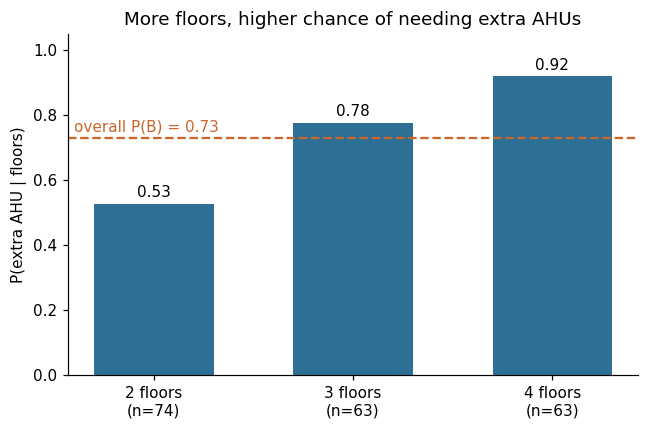

In [40]:
by_floor = {k: Pc(Bx, df[f'F{k}']) for k in (2, 3, 4)}
n_floor  = {k: int(df[f'F{k}'].sum()) for k in (2, 3, 4)}
overall  = Bx.mean()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([f'{k} floors\n(n={n_floor[k]})' for k in by_floor],
              list(by_floor.values()), color='#2E6F95', width=0.6)
ax.axhline(overall, color='#C8662B', ls='--', lw=1.5)
ax.text(-0.4, overall + 0.02, f'overall P(B) = {overall:.2f}', color='#C8662B', ha='left')
for b, v in zip(bars, by_floor.values()):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}', ha='center')
ax.set_ylim(0, 1.05)
ax.set_ylabel('P(extra AHU | floors)')
ax.set_title('More floors, higher chance of needing extra AHUs')
plt.tight_layout(); plt.savefig('figures/fig_m5_extra_ahu_by_floors.png', dpi=150); plt.show()

**Reading the chart.** The share of buildings needing extra AHUs rises with the number of floors: 0.53 for 2 floors, 0.78 for 3 and 0.92 for 4, around the overall P(B) = 0.73. This is the same pattern as the total probability calculation in 5.7, where these three conditional probabilities are weighted by the floor shares to give 0.73. A likely reason, from the data report, is that more floors mean more rooms, and the generator adds air handlers when a floor plan exceeds 10 rooms per AHU. This is an association in generated data, not proof that floors cause extra AHUs.

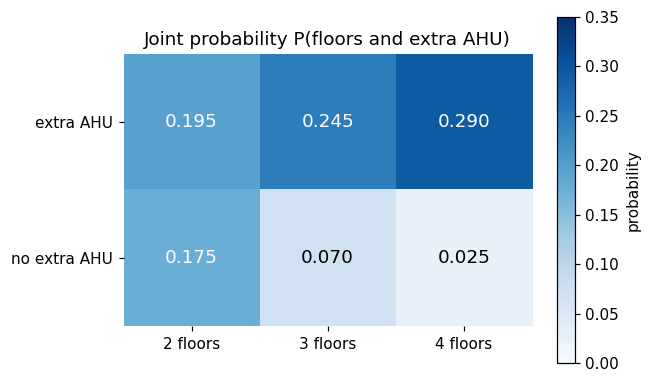

sum of all cells = 1.0 | top row sum = 0.73


In [41]:
import numpy as np

floors = (2, 3, 4)
joint = np.array([[ (df[f'F{k}'] & Bx).mean() for k in floors],     # extra AHU
                  [ (df[f'F{k}'] & ~Bx).mean() for k in floors]])   # no extra AHU

fig, ax = plt.subplots(figsize=(6, 3.6))
im = ax.imshow(joint, cmap='Blues', vmin=0, vmax=0.35)
ax.set_xticks(range(3)); ax.set_xticklabels([f'{k} floors' for k in floors])
ax.set_yticks(range(2)); ax.set_yticklabels(['extra AHU', 'no extra AHU'])
for i in range(2):
    for j in range(3):
        ax.text(j, i, f'{joint[i, j]:.3f}', ha='center', va='center', fontsize=12,
                color='white' if joint[i, j] > 0.17 else 'black')
ax.set_title('Joint probability P(floors and extra AHU)')
ax.spines[:].set_visible(False)
plt.colorbar(im, ax=ax, label='probability')
plt.tight_layout(); plt.savefig('figures/fig_m5_joint_heatmap.png', dpi=150); plt.show()
print('sum of all cells =', joint.sum().round(3), '| top row sum =', joint[0].sum().round(3))

**Reading the chart.** Each cell is a joint probability over all 200 buildings, so the six cells add up to 1. The top row adds to 0.195 + 0.245 + 0.290 = 0.730, which is P(extra AHU), the same answer the total probability rule gives in 5.7. The bottom row adds to 0.27. The weakest cell is 4 floors with no extra AHU (0.025, only 5 buildings): a 4-floor building almost always needs extra air handlers. The joint table shows where the buildings sit, and the conditional bars in the previous chart show how likely extra AHUs are within each floor group.

,threshold,n_large,P(B|large),P(B|not large)
0,40,171,0.830,0.138
1,50,139,0.921,0.295
2,64,98,0.990,0.480
3,80,69,1.000,0.588
4,100,45,1.000,0.652
5,120,31,1.000,0.680


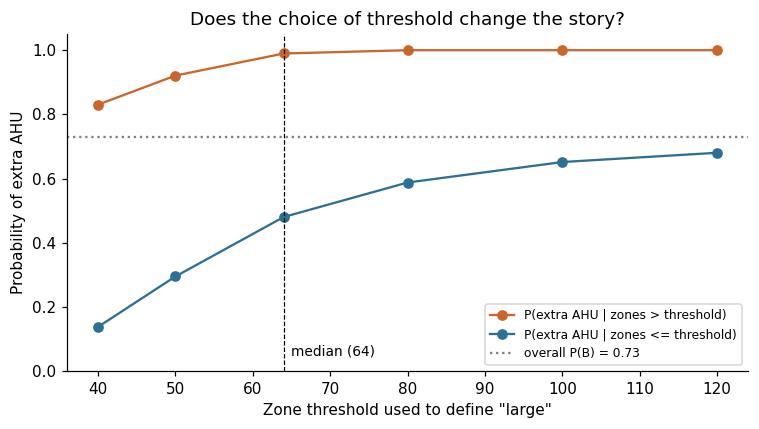

In [42]:
thresholds = [40, 50, 64, 80, 100, 120]
rows = []
for t in thresholds:
    big = df.n_zones > t
    rows.append((t, int(big.sum()), Pc(Bx, big), Pc(Bx, ~big)))
thr = pd.DataFrame(rows, columns=['threshold', 'n_large', 'P(B|large)', 'P(B|not large)'])
display(thr.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr.threshold, thr['P(B|large)'], marker='o', color='#C8662B', label='P(extra AHU | zones > threshold)')
ax.plot(thr.threshold, thr['P(B|not large)'], marker='o', color='#2E6F95', label='P(extra AHU | zones <= threshold)')
ax.axhline(Bx.mean(), color='grey', ls=':', label=f'overall P(B) = {Bx.mean():.2f}')
ax.axvline(64, color='black', lw=0.8, ls='--'); ax.text(65, 0.05, 'median (64)', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Zone threshold used to define "large"')
ax.set_ylabel('Probability of extra AHU')
ax.set_title('Does the choice of threshold change the story?')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig('figures/fig_m5_threshold_check.png', dpi=150); plt.show()

**Reading the chart.** The story does not depend on the 64-zone cut. At every threshold from 40 to 120 zones, large buildings need extra AHUs far more often than the rest. The gap between the two groups is 0.69 at 40 zones, 0.51 at 64 and 0.32 at 120. It shrinks because the "not large" group starts to include bigger buildings. Above 80 zones, every building in the data needed extra AHUs (P = 1.000). A possible reason is that the generator configures at most 7 AHUs and adds more when a floor plan exceeds 10 rooms per AHU, so very large plans always need extra. We chose the median because it splits the buildings almost evenly (98 vs 102), which gives stable estimates for both groups. At high thresholds the "large" group gets small (31 buildings at 120), so those values are less reliable.

## 7.1 Key insights

**1. Size almost guarantees extra AHUs.** P(extra AHU | large) = 97/98 = 0.990, against 49/102 = 0.480 for the other buildings and 0.730 overall. The 95% bootstrap interval for the 0.990 is about 0.967 to 1.000 (Section 6.3). The threshold check (threshold chart above) shows the gap stays large at every cut between 40 and 120 zones, so this does not depend on choosing 64.

**2. More floors means a higher rate of extra AHUs.** The rate is 0.53 for 2 floors, 0.78 for 3 and 0.92 for 4. The total probability rule (5.7) combines these with the floor shares to give the overall 0.730.

**3. Evidence of extra AHUs shifts our belief toward bigger buildings.** By Bayes' theorem (5.8), P(4 floors | extra AHU) = 58/146 = 0.397, up from the prior P(4 floors) = 0.315. In the same way, about two thirds of the buildings with extra AHUs are large (97/146 = 0.664).

**4. About 29% of the seeds the generator tries are rejected.** P(rejected) = 82/282 = 0.291, so organizers need about 1.4 seeds per usable building. Two out of three failures (54 of 82, 0.659) come from a single undersized zone.

**5. The settings the generator draws separately look independent; the outcomes do not.** Section 5.9 finds that floors, occupants and configured AHUs pair up consistently with independence, while extra-AHU status, size and floors are dependent. All dependent pairs trace back to one mechanism: the generator needs ceil(zones / 10) air handlers but configures only 3 to 7.

**6. The main result is stable.** Rule-based and direct counts agree exactly (6.1), the Monte Carlo and bootstrap checks agree within sampling noise, and removing the 10 largest buildings leaves P(extra AHU | large) at 0.989 (6.4). The one number that moves noticeably is P(4 floors | extra AHU), which falls from 0.397 to 0.360 after trimming, so it is the least robust of our results.

## 7.2 Assumptions and limitations

**What the data is**
- **Generator output, not real buildings.** Every probability describes this generator and this seed range (100000–100281). It says nothing about real buildings.
- **Conditional on acceptance.** Building-level results use only the 200 accepted seeds. The 82 rejected seeds appear only in the rejection-rate analysis (5.1 and 5.4), so a building the generator refuses to make can never show up in our results.
- **Small sample.** With n = 200, probabilities carry noise. The bootstrap interval for P(extra AHU | large) is about 0.967 to 1.000 (6.3), and cell-level counts can be tiny (for example, only 5 buildings with 4 floors and no extra AHU).
- **No outcome variable.** The files contain no energy use or comfort measure, so we can describe how complex a building is, but not how well a controller performs on it.

**How we modelled it**
- **Equally likely draws.** We treat seeds and buildings as equally likely outcomes. The generator is actually deterministic, so this is a modelling choice that lets us use counting-based probability.
- **Association, not cause.** The link between size and extra AHUs comes from a mechanical rule: the generator requires ceil(zones / 10) air handlers but configures only 3 to 7. This explains the pattern in generated data; it is not a finding about real buildings.
- **The median threshold is a convention.** We use 64 zones because it splits the buildings almost evenly (98 vs 102). The threshold chart shows the conclusion holds from 40 to 120 zones, but the numbers themselves change with the cut.
- **Independence is a judgement rule.** We call a pair "consistent with independence" when its gap is within 2 standard errors. With 200 rows this cannot prove independence.

**What the checks can and cannot show**
- **Validation checks our code, not the generator.** Monte Carlo and the bootstrap only redraw the same 200 rows, so they confirm our calculations and show sampling noise (6.1 to 6.3).
- **Trimming changes the population.** After removing the 10 largest buildings (6.4), results describe buildings up to 157.7 zones, not all accepted buildings.

**What is missing from the files**
- **17 of the 54 columns are constant, and several others are redundant** (for example n_zones equals n_vav_boxes). They carry no information for events.
- **The observation length (229 to 2,353 values) is derived by a formula.** It was checked against a live environment for only a few buildings, not for all 200.
- **One weather preset for every building.** Its effect on the floor plans was not tested.

## 7.3 Relevance for the competition

**1. Stratify the train/test split by size.** About 73% of generated buildings need extra AHUs (146 of 200), and nearly all large ones do (97 of 98). A random split could put most large buildings in one set. Splitting within the size groups keeps both sets balanced. Stratifying on size and extra-AHU status together is not practical, because only 1 building is large without extra AHUs.

**2. An easy-to-hard curriculum is justified.** The observation vector grows with building size, from 229 values (21 zones) to 2,353 (305 zones). Large buildings also almost always need extra AHUs. Zone count or observation length can therefore order the curriculum from easy to hard. We have no controller results, so "harder" here means a larger and more complex problem, not a measured one.

**3. The rejection rate tells organizers how many seeds to generate.** About 29% of seeds are rejected (82 of 282), so roughly 1.4 seeds are needed per usable building. For N buildings, generate about 1.4 × N seeds.

**4. The dependence structure shows which parameters to vary.** Floors, occupants and configured AHUs look independent, so they can be varied freely to cover the design space. Zone count and extra-AHU status depend on the layout, so they are better controlled through the generator's width and height ranges than set directly.

**5. Building complexity can be used as a target in later tasks.** The files have no energy or comfort outcome. Zone count, extra-AHU status and observation length can still serve as targets for the distribution, estimation and regression tasks, until rollout results are added.